# Results, graphs and benchmark - JK version vs. the paper

**Version used for structure:** the JK document *"Comprehensive Experimental Results and Analysis"* (Feb 2026): Tables 1-11 and Figures 1-3.
**Benchmark:** the numbers printed in the paper / JK (CCT, **17 classes incl. `car`**, 1,572 images).

Four runs are shown side by side (all zero-shot, same samples, seed 42):

| run | classes | activation | what it is |
|---|---|---|---|
| `16c-Q` | 16 animals | **QuickGELU** | **primary** (this notebook's headline; made by notebook `01`) |
| `16c-G` | 16 animals | GELU | notebook `01` |
| `17c-G` | 17 (with car) | GELU | the literal open_clip call, closest to the paper's setup |
| `17c-Q` | 17 (with car) | QuickGELU for the OpenAI models, GELU for BioCLIP (native) | earlier pipeline run |

Only the 17-class runs are directly comparable with the paper numbers; the 16-class runs have a different label set and chance level (6.25 % vs 5.9 %).
This notebook computes **everything from the saved per-image predictions** (no model is re-run here); all outputs go to `results/notebook_report/` and `figures/notebook_report/`.

## 0. Setup and data inventory

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mp
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from common import SEED, DATA, IMAGES, RESULTS, FIGURES, SPECIES, class_name
import paper_values as PV
from nbhelpers import MODELS, MODEL_COLORS, LEVELS, LEVEL_LABELS, PROMPT_KEYS, HABS, summarize, cds, acc, ps, cds_color, bootstrap_ci, ece

OUT, FIG = RESULTS / "notebook_report", FIGURES / "notebook_report"
for d in (OUT, FIG): d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
TABLES = {}
def save(name, df, index=True):
    TABLES[name] = df; df.to_csv(OUT / f"{name}.csv", index=index); return df

RES_A = RESULTS / "notebook_animal"
assert (RES_A / "all_predictions.csv").exists(), "run notebook 01_animal_only_quickgelu_gelu.ipynb first"
A = pd.read_csv(RES_A / "all_predictions.csv")
S16 = pd.read_csv(RES_A / "sample_points.csv")
metaA = json.loads((RES_A / "run_meta.json").read_text())
P17Q = pd.read_csv(RESULTS / "all_predictions.csv")
P17G = pd.read_csv(RESULTS / "plain_gelu" / "all_predictions.csv")
sample17 = pd.read_csv(DATA / "sample.csv")
RUNS = {"16c-Q": A[A.activation == "quickgelu"], "16c-G": A[A.activation == "gelu"], "17c-G": P17G, "17c-Q": P17Q}
PRIMARY = "16c-Q"
R = {k: summarize(v) for k, v in RUNS.items()}
S = lambda r: R[r]["summary"]
inv = pd.DataFrame({k: dict(rows=len(v), classes=v.species.nunique(), samples=v.sample_id.nunique(),
                            exp4_images=int(v[v.experiment == "exp4"].sample_id.nunique())) for k, v in RUNS.items()}).T
display(inv); save("00_run_inventory", inv)

,rows,classes,samples,exp4_images
16c-Q,53232,16,1472,80
16c-G,53232,16,1472,80
17c-G,56847,17,1572,85
17c-Q,56847,17,1572,85


,rows,classes,samples,exp4_images
16c-Q,53232,16,1472,80
16c-G,53232,16,1472,80
17c-G,56847,17,1572,85
17c-Q,56847,17,1572,85


## 1. Table 1 - species distribution of the evaluation set

In [2]:
t1 = pd.DataFrame({"paper_N": pd.Series(PV.PAPER_COUNTS), "ours_17class": sample17.species.value_counts(),
                   "ours_16class": S16.species.value_counts()}).sort_values("paper_N", ascending=False)
t1["match_paper"] = t1.paper_N == t1.ours_17class
t1["distinct_images"] = sample17.groupby("species").file_name.nunique()
display(t1); print(f"total: paper 1,572 | ours 17-class {len(sample17)} | 16-class {len(S16)}")
save("table01_species_distribution", t1)

,paper_N,ours_17class,ours_16class,match_paper,distinct_images
bird,100,100,100.0,True,98
lizard,100,100,100.0,True,100
bobcat,100,100,100.0,True,100
car,100,100,NaN,True,100
cat,100,100,100.0,True,100
coyote,100,100,100.0,True,100
deer,100,100,100.0,True,100
dog,100,100,100.0,True,100
fox,100,100,100.0,True,100
skunk,100,100,100.0,True,100


total: paper 1,572 | ours 17-class 1572 | 16-class 1472


,paper_N,ours_17class,ours_16class,match_paper,distinct_images
bird,100,100,100.0,True,98
lizard,100,100,100.0,True,100
bobcat,100,100,100.0,True,100
car,100,100,NaN,True,100
cat,100,100,100.0,True,100
coyote,100,100,100.0,True,100
deer,100,100,100.0,True,100
dog,100,100,100.0,True,100
fox,100,100,100.0,True,100
skunk,100,100,100.0,True,100


## 2. Table 2 - main results (Acc_full, Acc_UT, CDS, CR, PS, BG-only) vs. the paper
Acc/CR/PS/BG in %, CDS in %. Random baseline for BG-only: 5.9 % (17 classes) / 6.25 % (16 classes).

In [3]:
MET = ["acc_full", "acc_ultra_tight", "CDS", "CR", "PS", "BG_only"]
paper2 = pd.DataFrame(PV.TARGETS).T.rename(columns={"BG": "BG_only"})[MET].loc[MODELS]
SRC = ["Paper", "17c-G", "17c-Q", "16c-Q", "16c-G"]
t2 = pd.concat({s: (paper2 if s == "Paper" else S(s)[MET].loc[MODELS]) for s in SRC})
display(t2.round(1)); save("table02_main_results", t2.round(2))
d2 = pd.concat({s: (S(s)[MET].loc[MODELS] - paper2) for s in SRC[1:]})
display(Markdown("**Difference to the paper (ours - paper, percentage points).** Within +-2 pp = reproduced, 2-3 pp = close, > 3 pp = differs."))
display(d2.round(1).style.background_gradient(cmap="RdBu_r", vmin=-15, vmax=15).format("{:+.1f}")); save("table02_diff_to_paper", d2.round(2))

acc_full  acc_ultra_tight   CDS     CR    PS  BG_only
Paper ViT-B/32      33.2             34.5  -4.0   86.0  45.7     12.9
      ViT-L/14      62.5             54.1  13.4   70.0  25.2     16.5
      BioCLIP       40.4             25.4  37.0   46.5  37.4     11.8
17c-G ViT-B/32      34.5             36.6  -6.1  104.5  35.6      9.4
      ViT-L/14      63.0             55.8  11.5   78.1  16.5     15.3
      BioCLIP       42.6             27.7  34.8   45.2  34.4      3.5
17c-Q ViT-B/32      38.7             40.0  -3.3  107.6  47.3     14.1
      ViT-L/14      55.9             50.9   9.0   85.1  33.7     15.3
      BioCLIP       42.6             27.7  34.8   45.2  34.4      3.5
16c-Q ViT-B/32      36.8             38.2  -3.9  110.8  61.5     10.0
      ViT-L/14      59.2             53.9   9.1   84.9  25.8     11.2
      BioCLIP       45.0             31.0  31.2   43.6  49.0     13.8
16c-G ViT-B/32      32.3             34.5  -6.7  106.4  44.7      5.0
      ViT-L/14      65.2             57.5  11.9   77.2  15.5     11.2
      BioCLIP       45.5             29.6  34.9   45.2  34.4      3.8

**Difference to the paper (ours - paper, percentage points).** Within +-2 pp = reproduced, 2-3 pp = close, > 3 pp = differs.

acc_full  acc_ultra_tight   CDS     CR     PS  BG_only
      model                                                           
17c-G ViT-B/32      1.28             2.08 -2.09  18.55 -10.10    -3.49
      ViT-L/14      0.54             1.69 -1.90   8.13  -8.67    -1.21
      BioCLIP       2.16             2.34 -2.17  -1.31  -3.01    -8.27
17c-Q ViT-B/32      5.54             5.51  0.72  21.59   1.65     1.22
      ViT-L/14     -6.58            -3.21 -4.41  15.14   8.52    -1.21
      BioCLIP       2.16             2.34 -2.17  -1.31  -3.01    -8.27
16c-Q ViT-B/32      3.62             3.75  0.13  24.81  15.84    -2.90
      ViT-L/14     -3.26            -0.23 -4.34  14.94   0.60    -5.25
      BioCLIP       4.64             5.58 -5.78  -2.91  11.58     1.95
16c-G ViT-B/32     -0.86             0.01 -2.72  20.42  -0.96    -7.90
      ViT-L/14      2.72             3.37 -1.52   7.15  -9.71    -5.25
      BioCLIP       5.12             4.22 -2.07  -1.31  -3.01    -8.05

In [4]:
cis = {r: bootstrap_ci(RUNS[r]) for r in ("16c-Q", "17c-G")}
ci_tab = []
for r, c in cis.items():
    for _, x in c.iterrows():
        pv = {"acc_full": "acc_full", "acc_ultra_tight": "acc_ultra_tight", "CDS": "CDS", "CR": "CR", "PS": "PS", "BG_only": "BG"}.get(x.metric)
        paper_v = PV.TARGETS[x.model][pv] if pv else {"acc_baseline": PV.EXP2[x.model][0], "acc_mismatch": PV.EXP2[x.model][1]}[x.metric]
        ci_tab.append(dict(run=r, model=x.model, metric=x.metric, ours=round(x.value, 1), ci_lo=round(x.ci_lo, 1), ci_hi=round(x.ci_hi, 1),
                           paper=paper_v, paper_inside_ci=bool(x.ci_lo <= paper_v <= x.ci_hi)))
ci_tab = pd.DataFrame(ci_tab); save("table02_bootstrap_ci", ci_tab, index=False)
display(Markdown("**Bootstrap 95 % CIs (2,000 resamples of the samples) and whether the paper's value falls inside.**"))
display(ci_tab.pivot_table(index=["run", "model"], columns="metric", values="paper_inside_ci", aggfunc="first").astype(int).replace({1: "in", 0: "OUT"}))

**Bootstrap 95 % CIs (2,000 resamples of the samples) and whether the paper's value falls inside.**

metric         BG_only  CDS   CR   PS acc_baseline acc_full acc_mismatch  \
run   model                                                                
16c-Q BioCLIP       in  OUT   in  OUT          OUT      OUT           in   
      ViT-B/32      in   in  OUT  OUT          OUT      OUT           in   
      ViT-L/14      in  OUT  OUT   in          OUT      OUT           in   
17c-G BioCLIP      OUT   in   in   in           in       in           in   
      ViT-B/32      in   in  OUT   in           in       in          OUT   
      ViT-L/14      in   in  OUT  OUT           in       in          OUT   

metric         acc_ultra_tight  
run   model                     
16c-Q BioCLIP              OUT  
      ViT-B/32             OUT  
      ViT-L/14              in  
17c-G BioCLIP              OUT  
      ViT-B/32              in  
      ViT-L/14              in

## 3. Figures 1 and 2 - accuracy and confidence as context is removed (JK Fig. 1, 2; paper Fig. 1)
Solid = `16c-Q` (primary), dashed = `16c-G`, dotted = `17c-G`; black stars = the points printed in the paper.

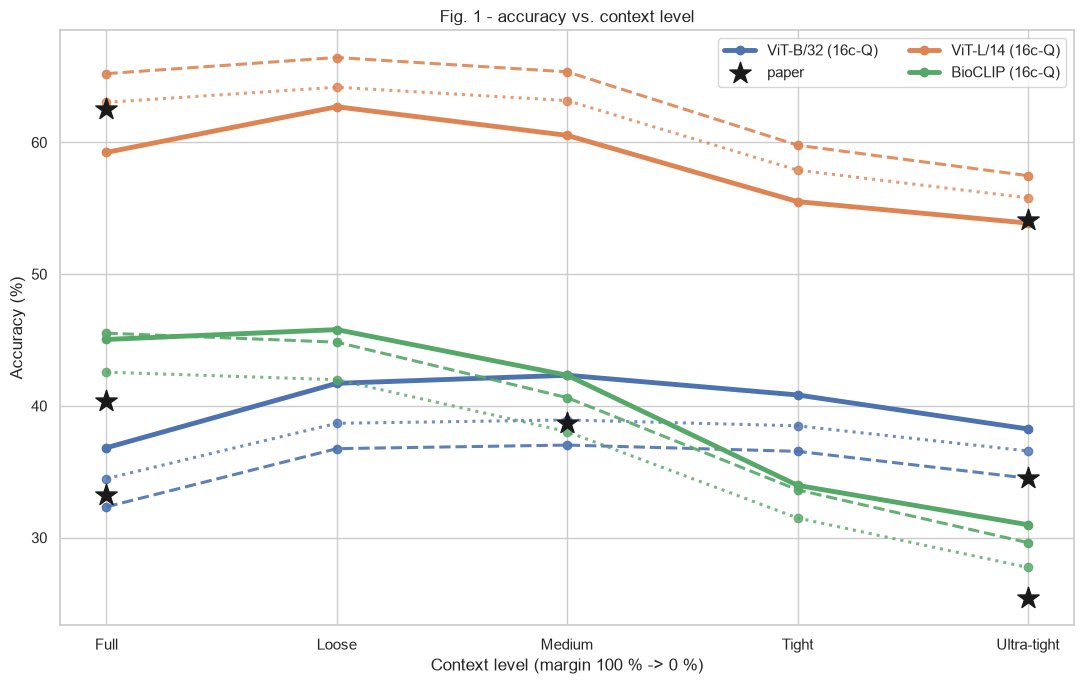

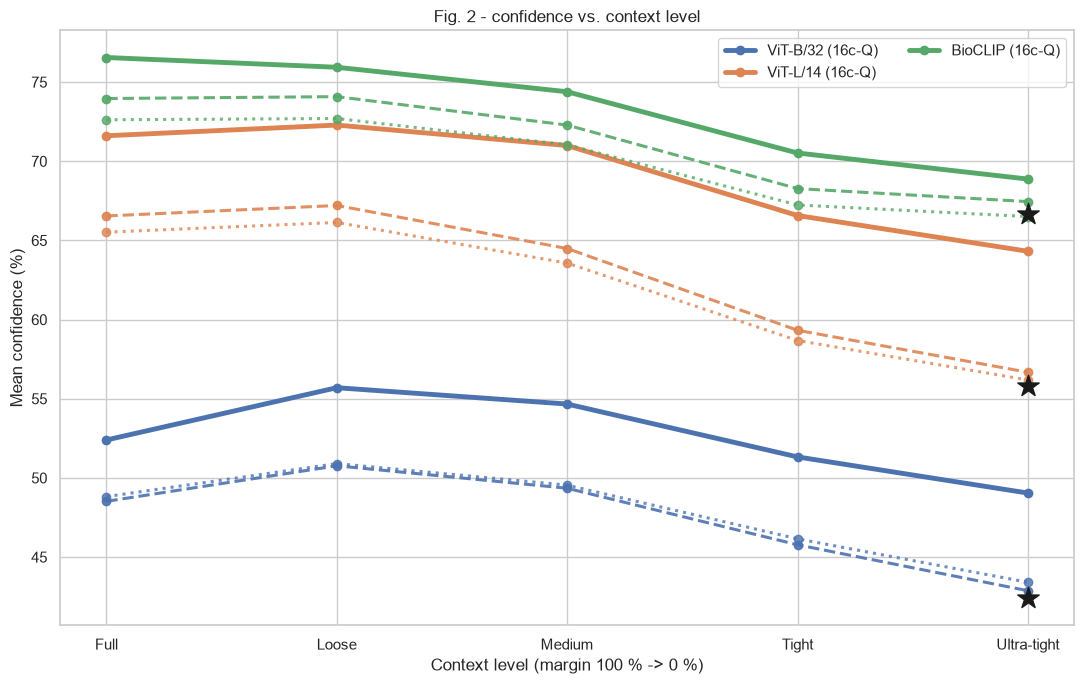

level           full  loose  medium  tight  ultra_tight
      model                                            
16c-Q ViT-B/32  36.8   41.7    42.3   40.8         38.2
      ViT-L/14  59.2   62.7    60.5   55.5         53.9
      BioCLIP   45.0   45.8    42.3   34.0         31.0
16c-G ViT-B/32  32.3   36.8    37.0   36.5         34.5
      ViT-L/14  65.2   66.4    65.4   59.8         57.5
      BioCLIP   45.5   44.8    40.6   33.6         29.6
17c-G ViT-B/32  34.5   38.7    38.9   38.5         36.6
      ViT-L/14  63.0   64.2    63.2   57.9         55.8
      BioCLIP   42.6   42.0    38.0   31.5         27.7
17c-Q ViT-B/32  38.7   43.3    43.9   42.5         40.0
      ViT-L/14  55.9   59.2    57.1   52.4         50.9
      BioCLIP   42.6   42.0    38.0   31.5         27.7

level           full  loose  medium  tight  ultra_tight
      model                                            
16c-Q ViT-B/32  52.4   55.7    54.7   51.3         49.0
      ViT-L/14  71.6   72.3    71.0   66.6         64.3
      BioCLIP   76.6   75.9    74.4   70.5         68.9
16c-G ViT-B/32  48.5   50.8    49.3   45.8         42.9
      ViT-L/14  66.5   67.2    64.5   59.3         56.7
      BioCLIP   74.0   74.1    72.3   68.3         67.5
17c-G ViT-B/32  48.8   50.9    49.5   46.2         43.4
      ViT-L/14  65.5   66.1    63.6   58.7         56.2
      BioCLIP   72.6   72.7    71.0   67.2         66.5
17c-Q ViT-B/32  53.1   56.1    55.1   51.9         49.8
      ViT-L/14  71.3   71.8    70.6   66.5         64.4
      BioCLIP   72.6   72.7    71.0   67.2         66.5

level            full  loose  medium  tight  ultra_tight
      model                                             
16c-Q ViT-B/32  52.40  55.70   54.67  51.33        49.04
      ViT-L/14  71.61  72.29   70.99  66.57        64.31
      BioCLIP   76.55  75.94   74.39  70.52        68.87
16c-G ViT-B/32  48.52  50.77   49.35  45.78        42.87
      ViT-L/14  66.55  67.21   64.49  59.32        56.67
      BioCLIP   73.96  74.08   72.29  68.27        67.45
17c-G ViT-B/32  48.82  50.90   49.54  46.15        43.41
      ViT-L/14  65.52  66.14   63.57  58.68        56.18
      BioCLIP   72.62  72.70   71.04  67.24        66.51
17c-Q ViT-B/32  53.05  56.13   55.13  51.92        49.77
      ViT-L/14  71.25  71.84   70.62  66.48        64.36
      BioCLIP   72.62  72.70   71.04  67.24        66.51

In [5]:
def level_plot(key, ylabel, title, paper_pts, fname):
    fig, ax = plt.subplots(figsize=(11, 7))
    for m in MODELS:
        for run, ls, lw, al in (("16c-Q", "-", 3.5, 1), ("16c-G", "--", 2.2, .9), ("17c-G", ":", 2.2, .8)):
            q = R[run]["levels"]; q = q[q.model == m].set_index("level").loc[LEVELS]
            ax.plot(LEVEL_LABELS, q[key], ls, marker="o", lw=lw, color=MODEL_COLORS[m], alpha=al, label=f"{m} ({run})" if run == "16c-Q" else None)
        for lvl, v in paper_pts.get(m, {}).items():
            ax.scatter(LEVELS.index(lvl), v, marker="*", s=260, color="k", zorder=5, label="paper" if (m == MODELS[0] and lvl == "full") else None)
    ax.set_ylabel(ylabel); ax.set_xlabel("Context level (margin 100 % -> 0 %)"); ax.set_title(title); ax.legend(ncol=2)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=170); plt.show()
level_plot("acc", "Accuracy (%)", "Fig. 1 - accuracy vs. context level", PV.PAPER_LEVEL_ACC, "fig01_accuracy_vs_context.png")
level_plot("conf", "Mean confidence (%)", "Fig. 2 - confidence vs. context level", PV.PAPER_LEVEL_CONF, "fig02_confidence_vs_context.png")
lv = pd.concat({r: R[r]["levels"].pivot(index="model", columns="level", values="acc")[LEVELS].loc[MODELS] for r in RUNS})
display(lv.round(1)); save("table_levels_accuracy", lv.round(2))
lc = pd.concat({r: R[r]["levels"].pivot(index="model", columns="level", values="conf")[LEVELS].loc[MODELS] for r in RUNS})
display(lc.round(1)); save("table_levels_confidence", lc.round(2))

In [6]:
# JK 3.2.2 "Overconfidence": confidence-accuracy gap at ultra-tight cropping and relative drops
rows = []
for r in ("16c-Q", "16c-G", "17c-G"):
    s = S(r)
    for m in MODELS:
        rows.append(dict(run=r, model=m, conf_UT=s.loc[m, "conf_ultra_tight"], acc_UT=s.loc[m, "acc_ultra_tight"], gap_pp=s.loc[m, "conf_acc_gap_ut"],
                         paper_gap_pp=PV.CONF_ACC_GAP_UT[m], conf_drop_pct=(s.loc[m, "conf_full"] - s.loc[m, "conf_ultra_tight"]) / s.loc[m, "conf_full"] * 100,
                         acc_drop_pct=s.loc[m, "CDS"]))
gap = pd.DataFrame(rows); display(gap.round(1)); save("table_confidence_gap", gap.round(2), index=False)

,run,model,conf_UT,acc_UT,gap_pp,paper_gap_pp,conf_drop_pct,acc_drop_pct
0,16c-Q,ViT-B/32,49.0,38.2,10.8,7.9,6.4,-3.9
1,16c-Q,ViT-L/14,64.3,53.9,10.4,1.7,10.2,9.1
2,16c-Q,BioCLIP,68.9,31.0,37.9,41.3,10.0,31.2
3,16c-G,ViT-B/32,42.9,34.5,8.4,7.9,11.6,-6.7
4,16c-G,ViT-L/14,56.7,57.5,-0.8,1.7,14.8,11.9
5,16c-G,BioCLIP,67.5,29.6,37.8,41.3,8.8,34.9
6,17c-G,ViT-B/32,43.4,36.6,6.8,7.9,11.1,-6.1
7,17c-G,ViT-L/14,56.2,55.8,0.4,1.7,14.3,11.5
8,17c-G,BioCLIP,66.5,27.7,38.8,41.3,8.4,34.8


,run,model,conf_UT,acc_UT,gap_pp,paper_gap_pp,conf_drop_pct,acc_drop_pct
0,16c-Q,ViT-B/32,49.04,38.25,10.80,7.9,6.40,-3.87
1,16c-Q,ViT-L/14,64.31,53.87,10.44,1.7,10.19,9.06
2,16c-Q,BioCLIP,68.87,30.98,37.90,41.3,10.03,31.22
3,16c-G,ViT-B/32,42.87,34.51,8.36,7.9,11.64,-6.72
4,16c-G,ViT-L/14,56.67,57.47,-0.80,1.7,14.84,11.88
5,16c-G,BioCLIP,67.45,29.62,37.83,41.3,8.80,34.93
6,17c-G,ViT-B/32,43.41,36.58,6.83,7.9,11.08,-6.09
7,17c-G,ViT-L/14,56.18,55.79,0.39,1.7,14.25,11.50
8,17c-G,BioCLIP,66.51,27.74,38.77,41.3,8.42,34.83


## 4. Table 3 / Figure 2 (paper) - per-species Context Dependency Score
Colour code (as in JK): **red** > 30 %, **orange** 15-30 %, **green** 0-15 %, **blue** negative. Species sorted by the paper's BioCLIP CDS.
Per-species CDS is defined as 0 where Acc_full = 0 (e.g. BioCLIP on `car`). Car appears only in the 17-class runs and the paper.

In [7]:
sp_cds = lambda r: R[r]["species"].pivot(index="species", columns="model", values="CDS")[MODELS]
paper_sp = pd.DataFrame(PV.SPECIES_CDS, index=MODELS).T
T3 = pd.concat({"Paper": paper_sp, "17c-G": sp_cds("17c-G"), "16c-Q": sp_cds("16c-Q"), "16c-G": sp_cds("16c-G")}, axis=1)
T3 = T3.reindex(paper_sp.sort_values("BioCLIP", ascending=False).index)
save("table03_per_species_cds", T3.round(1))
T3.style.map(lambda v: f"background-color:{cds_color(v)}").format("{:.1f}", na_rep="-")

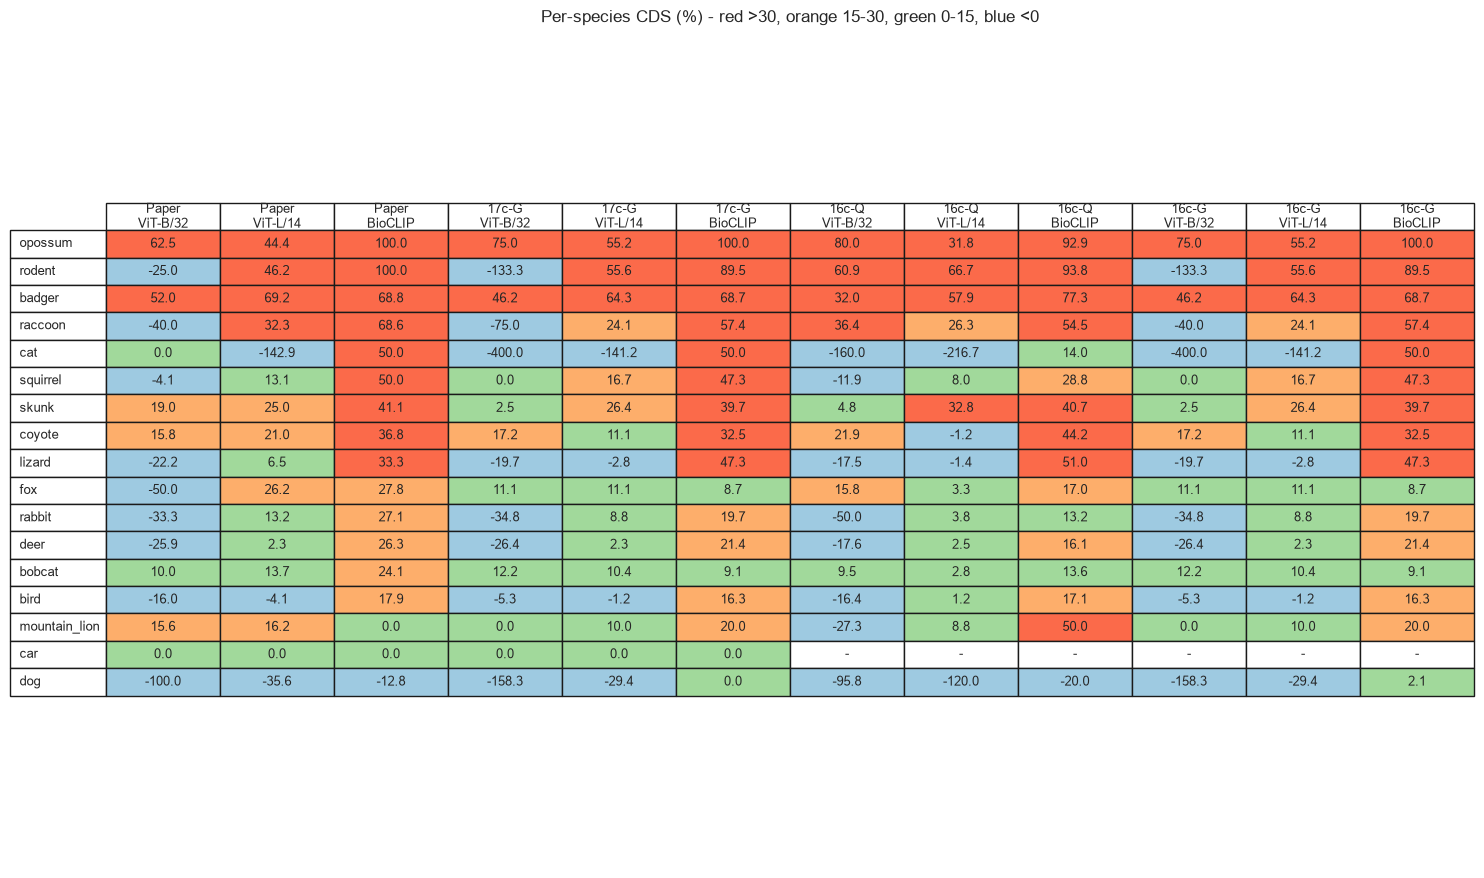

**Number of species with negative CDS** (16 species in the 16c runs, 17 in the 17c runs and the paper).

,16c-Q,16c-G,17c-G,17c-Q,"paper (of 17, from its Table 6)"
model,,,,,
ViT-B/32,8,8,8,8,9
ViT-L/14,4,4,4,4,3
BioCLIP,1,0,0,0,1


In [8]:
def color_table_fig(df, path, title, fontsize=9):
    fig, ax = plt.subplots(figsize=(1.0 * len(df.columns) + 3, 0.42 * len(df) + 1.8)); ax.axis("off")
    cell = [[("-" if np.isnan(v) else f"{v:.1f}") for v in row] for row in df.values]
    colors = [[cds_color(v) for v in row] for row in df.values]
    tb = ax.table(cellText=cell, cellColours=colors, rowLabels=list(df.index),
                  colLabels=[f"{a}\n{b}" for a, b in df.columns], loc="center", cellLoc="center")
    tb.auto_set_font_size(False); tb.set_fontsize(fontsize); tb.scale(1, 1.35)
    ax.set_title(title, fontsize=12); fig.tight_layout(); fig.savefig(path, dpi=170); plt.show()
color_table_fig(T3, FIG / "table03_per_species_cds_colored.png", "Per-species CDS (%) - red >30, orange 15-30, green 0-15, blue <0")
negs = pd.DataFrame({r: S(r).neg_cds_species for r in RUNS})
negs["paper (of 17, from its Table 6)"] = [9, 3, 1]
display(Markdown("**Number of species with negative CDS** (16 species in the 16c runs, 17 in the 17c runs and the paper).")); display(negs)

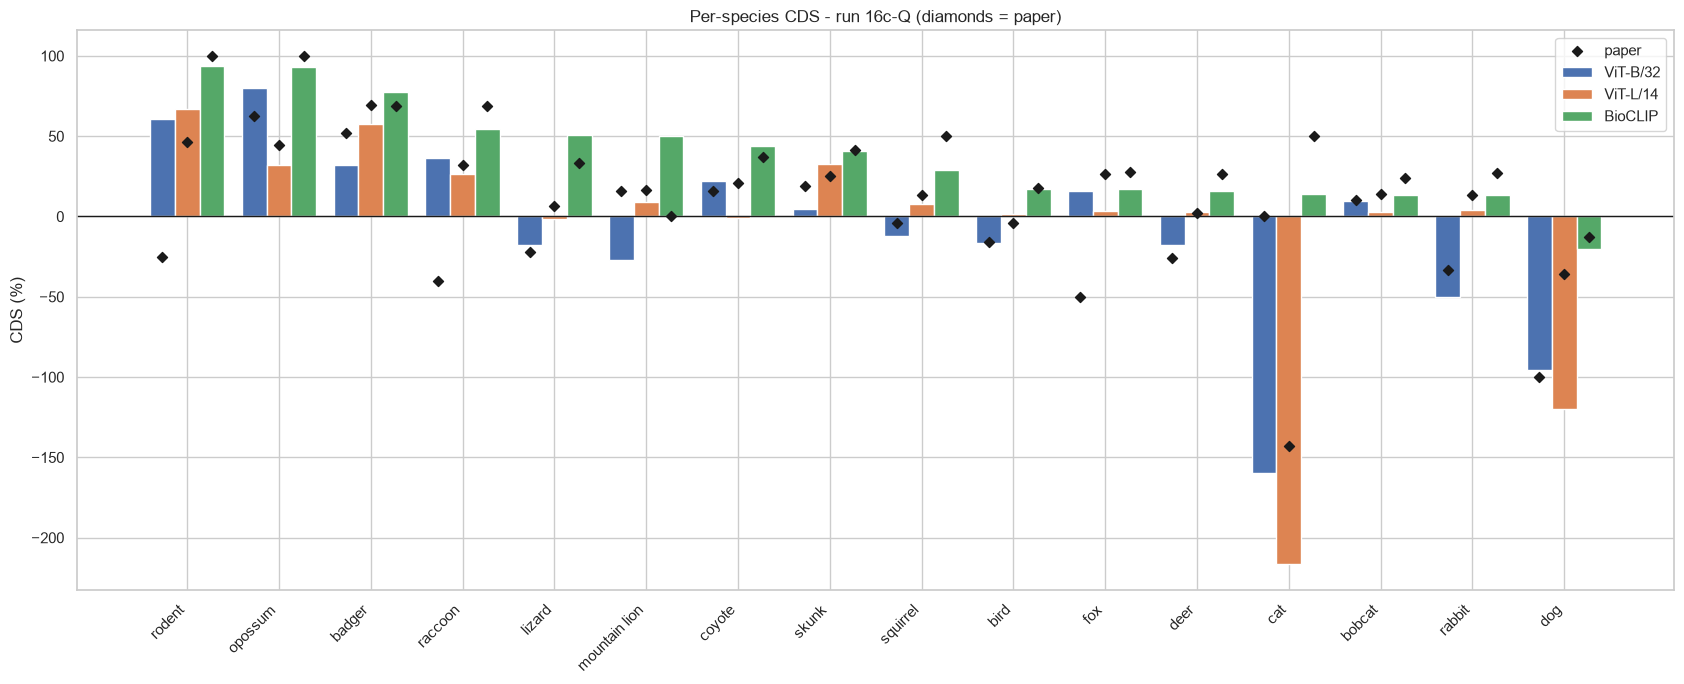

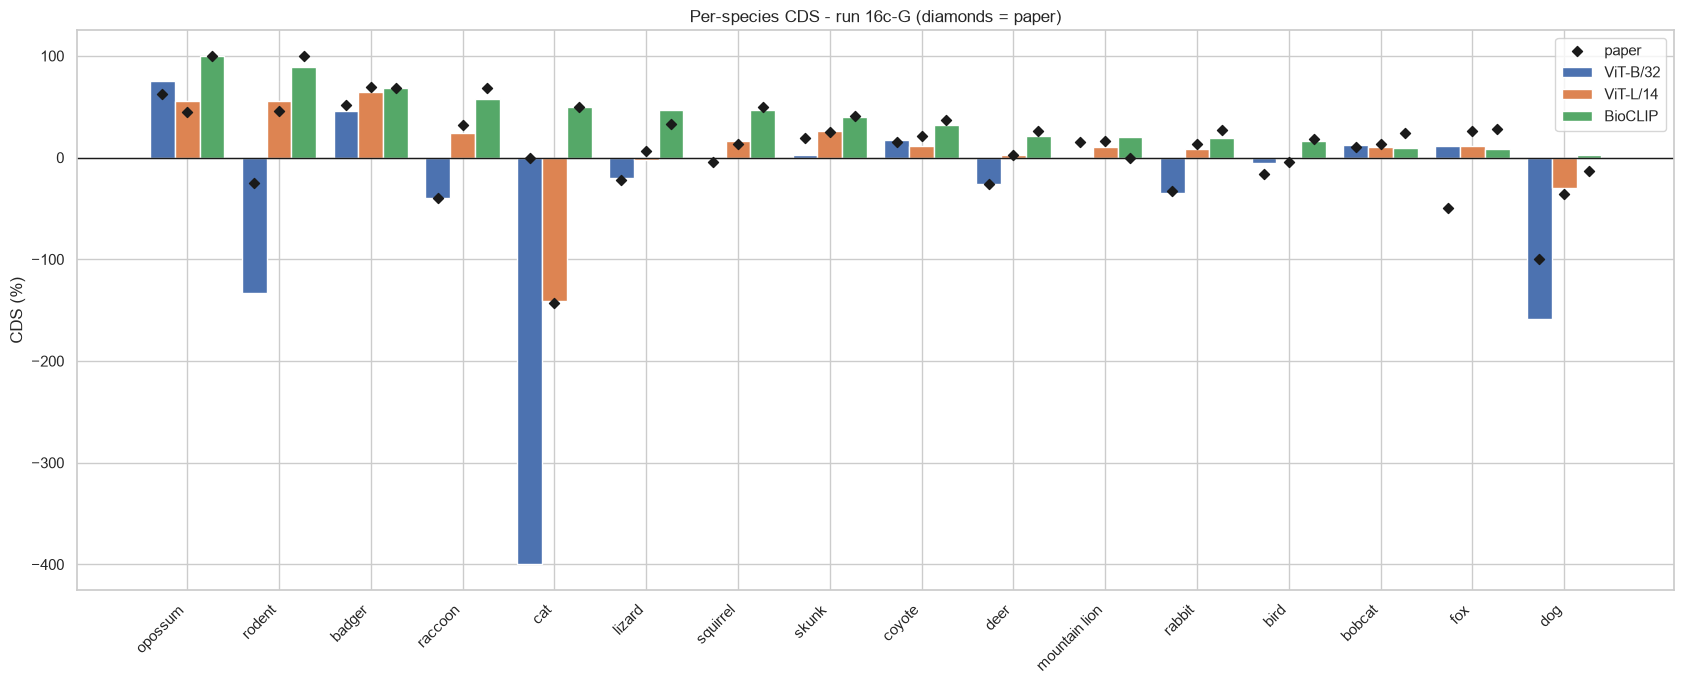

In [9]:
def cds_bars(run, fname):
    sp = sp_cds(run); order = sp.sort_values("BioCLIP", ascending=False).index
    fig, ax = plt.subplots(figsize=(17, 7)); w = 0.27; x = np.arange(len(order))
    for i, m in enumerate(MODELS):
        ax.bar(x + (i - 1) * w, sp.loc[order, m], w, color=MODEL_COLORS[m], label=m)
        pv = [PV.SPECIES_CDS[s][i] if s in PV.SPECIES_CDS else np.nan for s in order]
        ax.scatter(x + (i - 1) * w, pv, marker="D", s=26, color="k", zorder=5, label="paper" if i == 0 else None)
    ax.axhline(0, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels([class_name(s) for s in order], rotation=45, ha="right")
    ax.set_ylabel("CDS (%)"); ax.set_title(f"Per-species CDS - run {run} (diamonds = paper)"); ax.legend()
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=170); plt.show()
cds_bars("16c-Q", "fig03_per_species_cds_16cQ.png"); cds_bars("16c-G", "fig03_per_species_cds_16cG.png")

## 5. Experiment 2 - context mismatch (JK Tables 4, 5, 11)
Baseline = original uncropped images with the neutral prompt; mismatch = the animal's box pasted on a wrong-habitat synthetic background.
The species-to-habitat mapping is **reconstructed** (no earlier mapping survived); it reproduces the paper's per-habitat totals (1,172 / 672 / 1,000 / 300) in the 17-class design.

In [10]:
hm = pd.read_csv(RES_A / "habitat_mapping.csv"); display(hm)
rows = []
for r in ("17c-G", "17c-Q", "16c-Q", "16c-G"):
    s = S(r)
    for m in MODELS:
        rows.append(dict(run=r, model=m, baseline=s.loc[m, "acc_baseline"], mismatch=s.loc[m, "acc_mismatch"], CR=s.loc[m, "CR"], n=int(s.loc[m, "n_mismatch"])))
for m in MODELS:
    rows.append(dict(run="Paper", model=m, baseline=PV.EXP2[m][0], mismatch=PV.EXP2[m][1], CR=PV.TARGETS[m]["CR"], n=3144))
t4 = pd.DataFrame(rows).set_index(["run", "model"]).loc[["Paper", "17c-G", "17c-Q", "16c-Q", "16c-G"]]
display(t4.round(1)); save("table04_context_robustness", t4.round(2))
display(Markdown("CR > 100 % means accuracy on wrong-habitat composites is *higher* than on the originals (a model that is helped by removing clutter)."))

,species,habitat_1,habitat_2,rationale,n_samples
0,badger,arctic,desert,required by task (burrowing woodland/grassland...,28
1,mountain_lion,arctic,desert,required by task,44
2,opossum,arctic,desert,"warm-temperate woodland species, poorly adapte...",100
3,raccoon,arctic,desert,riparian/woodland species; snow and dry sand a...,100
4,squirrel,arctic,desert,forest/tree-dependent species,100
5,bobcat,arctic,urban,solitary forest/scrub carnivore; avoids dense ...,100
6,deer,arctic,urban,task: no aquatic for deer; woodland browser,100
7,lizard,aquatic,urban,"task: no desert for lizard; ectotherm, not aqu...",100
8,bird,arctic,aquatic,"terrestrial passerine/quail-type birds, not sn...",100
9,coyote,arctic,aquatic,desert/scrub-adapted canid,100


baseline  mismatch     CR     n
run   model                                    
Paper ViT-B/32      18.8      16.2   86.0  3144
      ViT-L/14      40.2      28.1   70.0  3144
      BioCLIP       24.8      11.5   46.5  3144
17c-G ViT-B/32      18.2      19.0  104.5  3144
      ViT-L/14      41.2      32.2   78.1  3144
      BioCLIP       24.5      11.1   45.2  3144
17c-Q ViT-B/32      18.4      19.8  107.6  3144
      ViT-L/14      34.0      29.0   85.1  3144
      BioCLIP       24.5      11.1   45.2  3144
16c-Q ViT-B/32      15.1      16.7  110.8  2944
      ViT-L/14      35.9      30.5   84.9  2944
      BioCLIP       28.6      12.5   43.6  2944
16c-G ViT-B/32      14.8      15.8  106.4  2944
      ViT-L/14      41.8      32.2   77.2  2944
      BioCLIP       26.2      11.8   45.2  2944

CR > 100 % means accuracy on wrong-habitat composites is *higher* than on the originals (a model that is helped by removing clutter).

habitat                   arctic           desert           aquatic  \
run   model                                                           
16c-G BioCLIP   122/1172 (10.4%)    38/572 (6.6%)   121/900 (13.4%)   
      ViT-B/32  203/1172 (17.3%)    37/572 (6.5%)   152/900 (16.9%)   
      ViT-L/14  343/1172 (29.3%)  165/572 (28.8%)   329/900 (36.6%)   
16c-Q BioCLIP   134/1172 (11.4%)    45/572 (7.9%)   132/900 (14.7%)   
      ViT-B/32  198/1172 (16.9%)   71/572 (12.4%)   154/900 (17.1%)   
      ViT-L/14  362/1172 (30.9%)  127/572 (22.2%)   286/900 (31.8%)   
17c-G BioCLIP   122/1172 (10.4%)    38/672 (5.7%)  121/1000 (12.1%)   
      ViT-B/32  203/1172 (17.3%)  104/672 (15.5%)  219/1000 (21.9%)   
      ViT-L/14  343/1172 (29.3%)  196/672 (29.2%)  360/1000 (36.0%)   

habitat                   urban  
run   model                      
16c-G BioCLIP    67/300 (22.3%)  
      ViT-B/32   72/300 (24.0%)  
      ViT-L/14  112/300 (37.3%)  
16c-Q BioCLIP    56/300 (18.7%)  
      ViT-B/32   69/300 (23.0%)  
      ViT-L/14  122/300 (40.7%)  
17c-G BioCLIP    67/300 (22.3%)  
      ViT-B/32   72/300 (24.0%)  
      ViT-L/14  112/300 (37.3%)

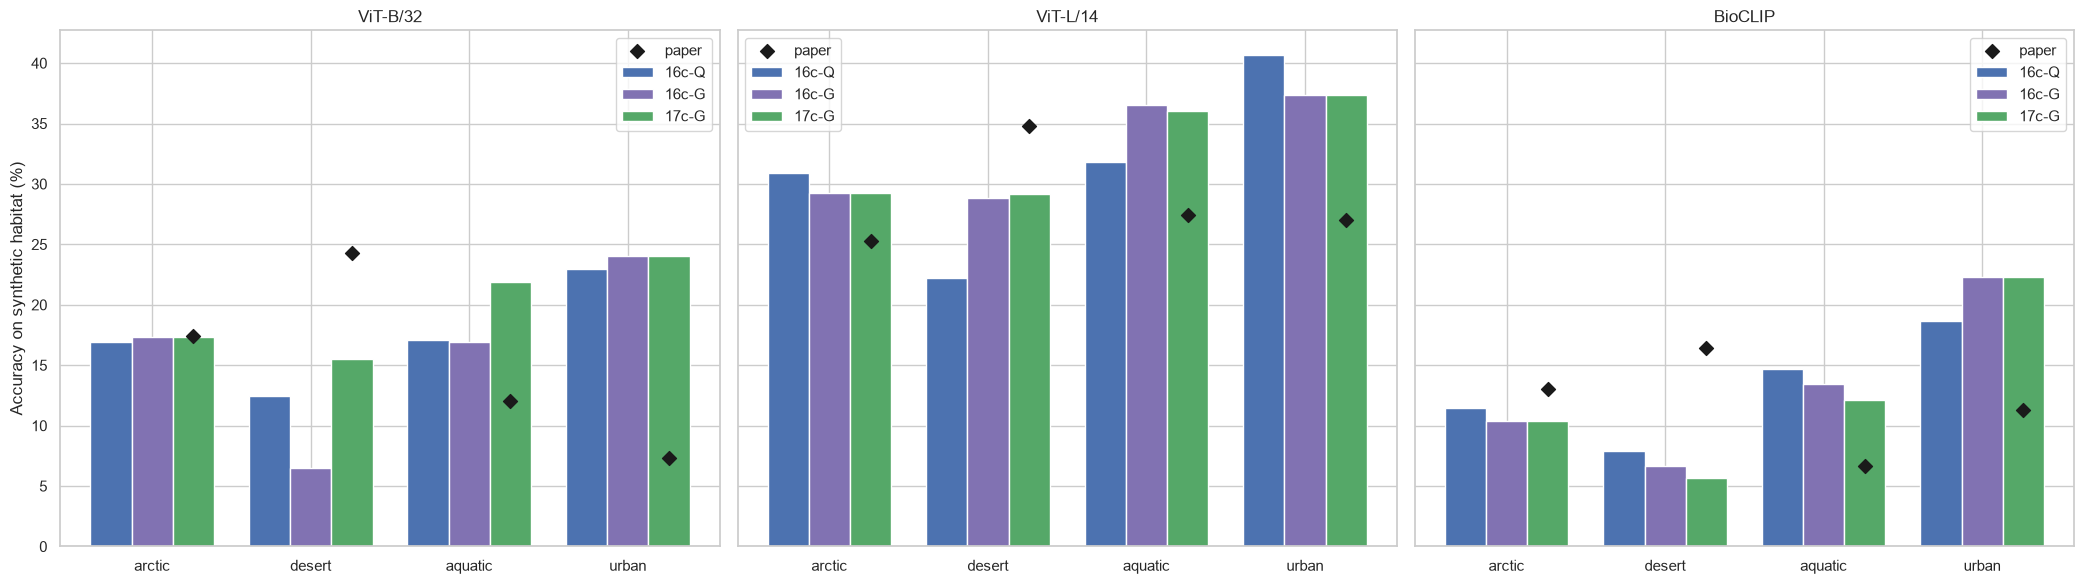

In [11]:
rows = []
for r in ("17c-G", "16c-Q", "16c-G"):
    h = R[r]["habitat"]
    for m in MODELS:
        for hb in HABS:
            x = h[(h.model == m) & (h.habitat == hb)]
            rows.append(dict(run=r, model=m, habitat=hb, correct=int(x.correct.iloc[0]), total=int(x.total.iloc[0]), acc=float(x.acc.iloc[0]),
                             paper_acc=PV.HABITAT_ACC[m][hb] if r.startswith("17") else np.nan))
t5 = pd.DataFrame(rows); save("table05_per_habitat", t5.round(2), index=False)
t5["cell"] = t5.correct.astype(str) + "/" + t5.total.astype(str) + " (" + t5.acc.round(1).astype(str) + "%)"
display(t5.pivot(index=["run", "model"], columns="habitat", values="cell")[HABS])
fig, axs = plt.subplots(1, 3, figsize=(21, 6), sharey=True)
for ax, m in zip(axs, MODELS):
    x = np.arange(4)
    for k, (r, c) in enumerate((("16c-Q", "#4c72b0"), ("16c-G", "#8172b2"), ("17c-G", "#55a868"))):
        q = t5[(t5.run == r) & (t5.model == m)].set_index("habitat").loc[HABS]
        ax.bar(x + (k - 1) * 0.26, q.acc, 0.26, color=c, label=r)
    ax.scatter(x + 0.26, [PV.HABITAT_ACC[m][h] for h in HABS], marker="D", color="k", s=50, zorder=5, label="paper")
    ax.set_xticks(x); ax.set_xticklabels(HABS); ax.set_title(m); ax.legend()
axs[0].set_ylabel("Accuracy on synthetic habitat (%)"); fig.tight_layout(); fig.savefig(FIG / "fig_mismatch_per_habitat.png", dpi=170); plt.show()

## 6. Experiment 3 - prompts (JK Table 6, Table 10) and Prompt Sensitivity
**PS = (max - min) / mean x 100.** The check below recomputes the paper's printed PS from the paper's own Table 4 accuracies with three possible denominators:
only the *mean* reproduces the printed values, so the paper's formula is right.

,paper_PS_printed,recomputed_mean_denominator,recomputed_max_denominator,recomputed_min_denominator
model,,,,
ViT-B/32,45.7,45.63,34.88,53.55
ViT-L/14,25.2,25.28,22.60,29.20
BioCLIP,37.4,37.52,29.84,42.53


neutral  habitat  wildlife  scientific    PS      best  \
run   model                                                              
Paper ViT-B/32     18.8     20.7      28.1        18.3  45.6  wildlife   
      ViT-L/14     40.2     44.3      46.9        36.3  25.3  wildlife   
      BioCLIP      24.8     18.4      17.4        18.3  37.5   neutral   
17c-G ViT-B/32     18.2     21.6      25.8        19.5  35.6  wildlife   
      ViT-L/14     41.2     46.5      48.3        41.0  16.5  wildlife   
      BioCLIP      24.5     17.6      19.2        18.6  34.4   neutral   
17c-Q ViT-B/32     18.4     19.8      28.8        20.5  47.3  wildlife   
      ViT-L/14     34.0     43.1      47.5        34.6  33.7  wildlife   
      BioCLIP      24.5     17.6      19.2        18.6  34.4   neutral   
16c-Q ViT-B/32     15.1     17.3      26.6        16.1  61.5  wildlife   
      ViT-L/14     35.9     44.1      45.2        34.9  25.8  wildlife   
      BioCLIP      28.6     18.4      18.0        21.5  49.0   neutral   
16c-G ViT-B/32     14.8     19.1      22.9        15.5  44.7  wildlife   
      ViT-L/14     41.8     45.4      45.7        39.1  15.5  wildlife   
      BioCLIP      26.2     18.8      20.5        19.8  34.4   neutral   

                     worst  
run   model                 
Paper ViT-B/32  scientific  
      ViT-L/14  scientific  
      BioCLIP     wildlife  
17c-G ViT-B/32     neutral  
      ViT-L/14  scientific  
      BioCLIP      habitat  
17c-Q ViT-B/32     neutral  
      ViT-L/14     neutral  
      BioCLIP      habitat  
16c-Q ViT-B/32     neutral  
      ViT-L/14  scientific  
      BioCLIP     wildlife  
16c-G ViT-B/32     neutral  
      ViT-L/14  scientific  
      BioCLIP      habitat

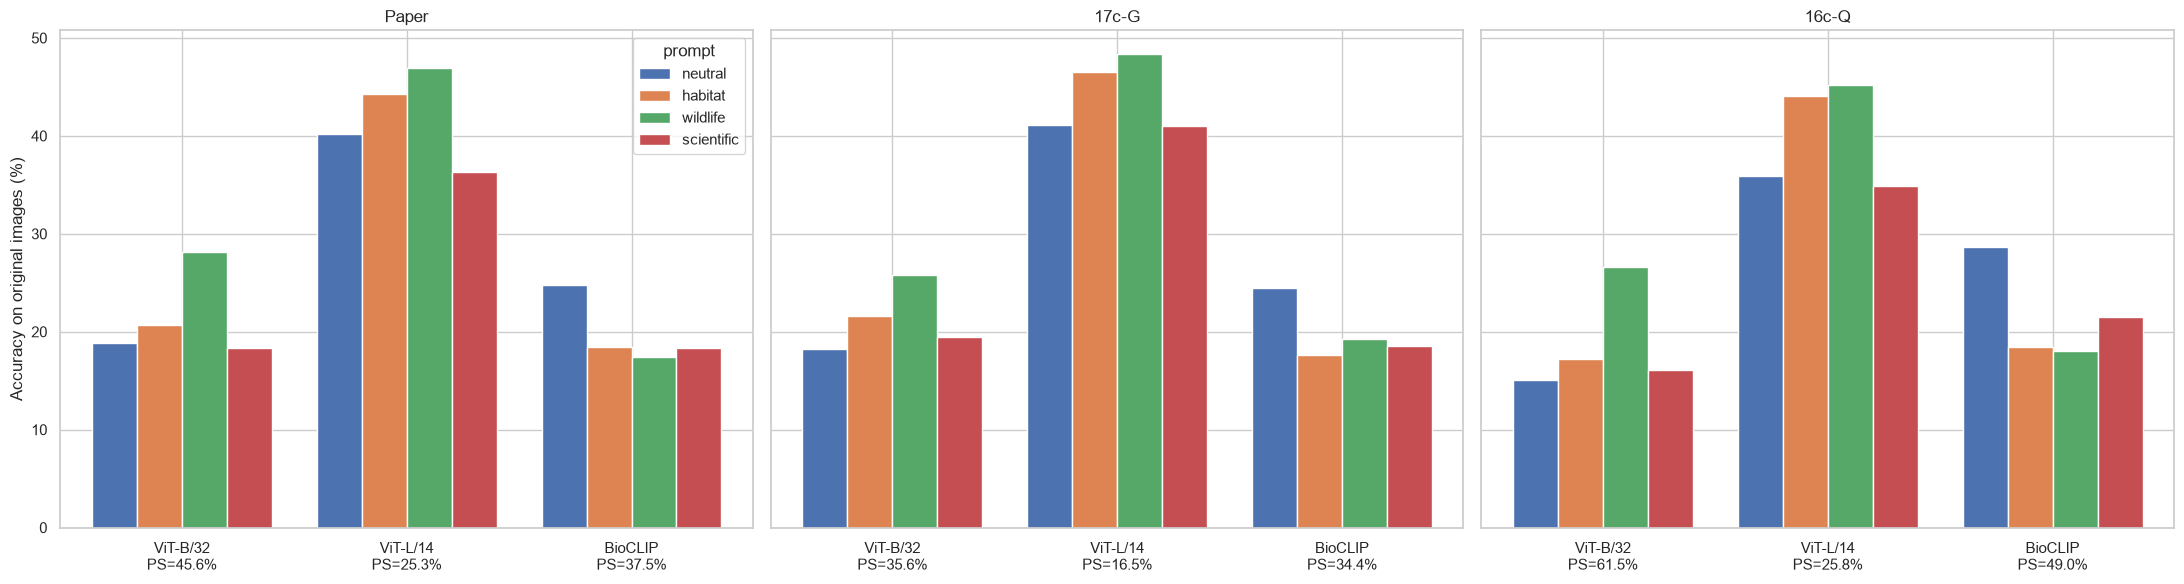

In [12]:
rows = []
for m in MODELS:
    pa = list(PV.PROMPT_ACC[m].values())
    rows.append(dict(model=m, paper_PS_printed=PV.TARGETS[m]["PS"], recomputed_mean_denominator=ps(pa),
                     recomputed_max_denominator=(max(pa) - min(pa)) / max(pa) * 100, recomputed_min_denominator=(max(pa) - min(pa)) / min(pa) * 100))
psc = pd.DataFrame(rows).set_index("model"); display(psc.round(2)); save("table_ps_formula_check", psc.round(2))
rows = []
for r in ("Paper", "17c-G", "17c-Q", "16c-Q", "16c-G"):
    for m in MODELS:
        if r == "Paper": a = PV.PROMPT_ACC[m]
        else: a = R[r]["prompts"].query("model == @m").set_index("prompt").acc.to_dict()
        rows.append(dict(run=r, model=m, **{k: a[k] for k in PROMPT_KEYS}, PS=ps([a[k] for k in PROMPT_KEYS]),
                         best=max(a, key=a.get), worst=min(a, key=a.get)))
t6 = pd.DataFrame(rows).set_index(["run", "model"]); display(t6.round(1)); save("table06_prompts", t6.round(2))
fig, axs = plt.subplots(1, 3, figsize=(22, 6), sharey=True)
for ax, r in zip(axs, ("Paper", "17c-G", "16c-Q")):
    for i, k in enumerate(PROMPT_KEYS):
        ax.bar(np.arange(3) + (i - 1.5) * 0.2, [t6.loc[(r, m), k] for m in MODELS], 0.2, label=k)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{m}\nPS={t6.loc[(r, m), 'PS']:.1f}%" for m in MODELS]); ax.set_title(r)
axs[0].set_ylabel("Accuracy on original images (%)"); axs[0].legend(title="prompt"); fig.tight_layout()
fig.savefig(FIG / "fig_prompt_sensitivity.png", dpi=170); plt.show()

In [13]:
# JK Table 10: ViT-L/14 per-species accuracy by prompt (best overall model)
def l14_prompt(r):
    q = R[r]["species_prompt"]; return q[q.model == "ViT-L/14"].pivot(index="species", columns="prompt", values="acc")[PROMPT_KEYS]
paper10 = pd.DataFrame(PV.TABLE10_L14, index=PROMPT_KEYS).T
t10 = pd.concat({"Paper": paper10, "17c-G": l14_prompt("17c-G"), "16c-Q": l14_prompt("16c-Q"), "16c-G": l14_prompt("16c-G")}, axis=1).reindex(paper10.index)
display(t10.round(1).style.format("{:.1f}", na_rep="-").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=100)); save("table10_L14_per_species_prompt", t10.round(1))

Paper                               17c-G                   \
              neutral habitat wildlife scientific neutral habitat wildlife   
mountain_lion    90.9    93.2     95.5       95.5    88.6    72.7     84.1   
deer             75.0    75.0     72.0       69.0    74.0    81.0     68.0   
skunk            64.0    81.0     68.0       63.0    60.0    76.0     67.0   
coyote           65.0    53.0     54.0       49.0    60.0    49.0     47.0   
bobcat           61.0    40.0     39.0       39.0    60.0    50.0     52.0   
fox              35.0    55.0     40.0       53.0    32.0    41.0     36.0   
opossum          51.0    41.0     73.0       25.0    51.0    43.0     73.0   
dog              25.0    49.0     55.0       23.0    25.0    52.0     56.0   
raccoon          47.0    43.0     25.0       28.0    57.0    53.0     31.0   
bird             44.0    42.0     42.0       28.0    50.0    52.0     54.0   
cat               2.0    24.0     44.0        4.0     2.0    30.0     40.0   
rabbit           33.0    33.0     37.0       27.0    23.0    29.0     32.0   
car              28.0    59.0     90.0       43.0    32.0    63.0     94.0   
badger           25.0     3.6     10.7       14.3    25.0     3.6     10.7   
rodent           11.0    15.0     10.0       28.0    23.0    30.0     22.0   
squirrel         23.0    23.0     21.0       23.0    29.0    26.0     26.0   
lizard           21.0    21.0     22.0       23.0    23.0    23.0     22.0   

                           16c-Q                               16c-G          \
              scientific neutral habitat wildlife scientific neutral habitat   
mountain_lion       95.5    65.9    31.8     65.9       56.8    88.6    72.7   
deer                67.0    65.0    73.0     69.0       60.0    74.0    81.0   
skunk               60.0    56.0    68.0     72.0       58.0    60.0    76.0   
coyote              55.0    61.0    61.0     57.0       39.0    60.0    49.0   
bobcat              52.0    68.0    77.0     51.0       81.0    60.0    50.0   
fox                 44.0    23.0    30.0     29.0       51.0    32.0    41.0   
opossum             23.0    54.0    59.0     72.0        1.0    51.0    43.0   
dog                 22.0     5.0    54.0     54.0       19.0    25.0    52.0   
raccoon             40.0    40.0    40.0     33.0       42.0    57.0    53.0   
bird                42.0    39.0    47.0     54.0       38.0    50.0    52.0   
cat                 11.0     0.0    16.0     32.0        2.0     2.0    30.0   
rabbit              20.0    24.0    28.0     36.0       19.0    23.0    29.0   
car                 70.0     NaN     NaN      NaN        NaN     NaN     NaN   
badger              14.3    46.4    42.9     25.0       28.6    25.0     3.6   
rodent              39.0    15.0    27.0     28.0       40.0    23.0    30.0   
squirrel            28.0    16.0    21.0     22.0       15.0    29.0    26.0   
lizard              26.0    20.0    22.0     21.0       16.0    23.0    23.0   

                                   
              wildlife scientific  
mountain_lion     84.1       95.5  
deer              69.0       67.0  
skunk             67.0       60.0  
coyote            48.0       55.0  
bobcat            54.0       52.0  
fox               36.0       44.0  
opossum           73.0       23.0  
dog               57.0       22.0  
raccoon           31.0       40.0  
bird              55.0       42.0  
cat               40.0       11.0  
rabbit            32.0       20.0  
car                NaN        NaN  
badger            14.3       14.3  
rodent            22.0       39.0  
squirrel          26.0       28.0  
lizard            22.0       26.0

## 7. Experiment 4 - background-only prediction (JK Table 7)

,,bg_only,n,correct,random,above_random_pp,paper
run,model,,,,,,
17c-G,ViT-B/32,9.4,85,8,5.9,3.5,12.9
16c-Q,ViT-B/32,10.0,80,8,6.2,3.8,12.9
16c-G,ViT-B/32,5.0,80,4,6.2,-1.2,12.9
17c-G,ViT-L/14,15.3,85,13,5.9,9.4,16.5
16c-Q,ViT-L/14,11.2,80,9,6.2,5.0,16.5
16c-G,ViT-L/14,11.2,80,9,6.2,5.0,16.5
17c-G,BioCLIP,3.5,85,3,5.9,-2.4,11.8
16c-Q,BioCLIP,13.8,80,11,6.2,7.5,11.8
16c-G,BioCLIP,3.8,80,3,6.2,-2.5,11.8


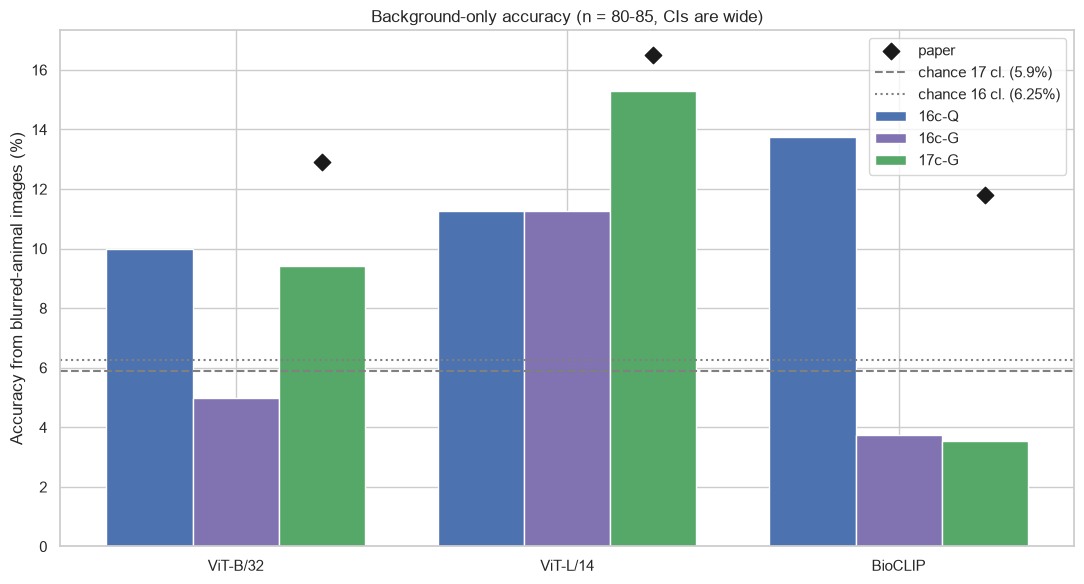

In [14]:
ci = cis["16c-Q"].query("metric == 'BG_only'").set_index("model")
rows = []
for m in MODELS:
    for r in ("17c-G", "16c-Q", "16c-G"):
        s = S(r); n = int(s.loc[m, "n_bg"]); rnd = 100 / s.n_species.iloc[0]
        rows.append(dict(run=r, model=m, bg_only=s.loc[m, "BG_only"], n=n, correct=int(round(s.loc[m, "BG_only"] / 100 * n)),
                         random=rnd, above_random_pp=s.loc[m, "BG_only"] - rnd, paper=PV.TARGETS[m]["BG"]))
t7 = pd.DataFrame(rows).set_index(["run", "model"]); display(t7.round(1)); save("table07_bg_only", t7.round(2))
fig, ax = plt.subplots(figsize=(11, 6))
for k, (r, c) in enumerate((("16c-Q", "#4c72b0"), ("16c-G", "#8172b2"), ("17c-G", "#55a868"))):
    ax.bar(np.arange(3) + (k - 1) * 0.26, [t7.loc[(r, m), "bg_only"] for m in MODELS], 0.26, color=c, label=r)
ax.scatter(np.arange(3) + 0.26, [PV.TARGETS[m]["BG"] for m in MODELS], marker="D", s=70, color="k", zorder=5, label="paper")
ax.axhline(100 / 17, color="grey", ls="--", label="chance 17 cl. (5.9%)"); ax.axhline(100 / 16, color="grey", ls=":", label="chance 16 cl. (6.25%)")
ax.set_xticks(range(3)); ax.set_xticklabels(MODELS); ax.set_ylabel("Accuracy from blurred-animal images (%)"); ax.legend(); ax.set_title("Background-only accuracy (n = 80-85, CIs are wide)")
fig.tight_layout(); fig.savefig(FIG / "fig_background_only.png", dpi=170); plt.show()

## 8. Confusion matrices (paper Fig. 3) - full-context images

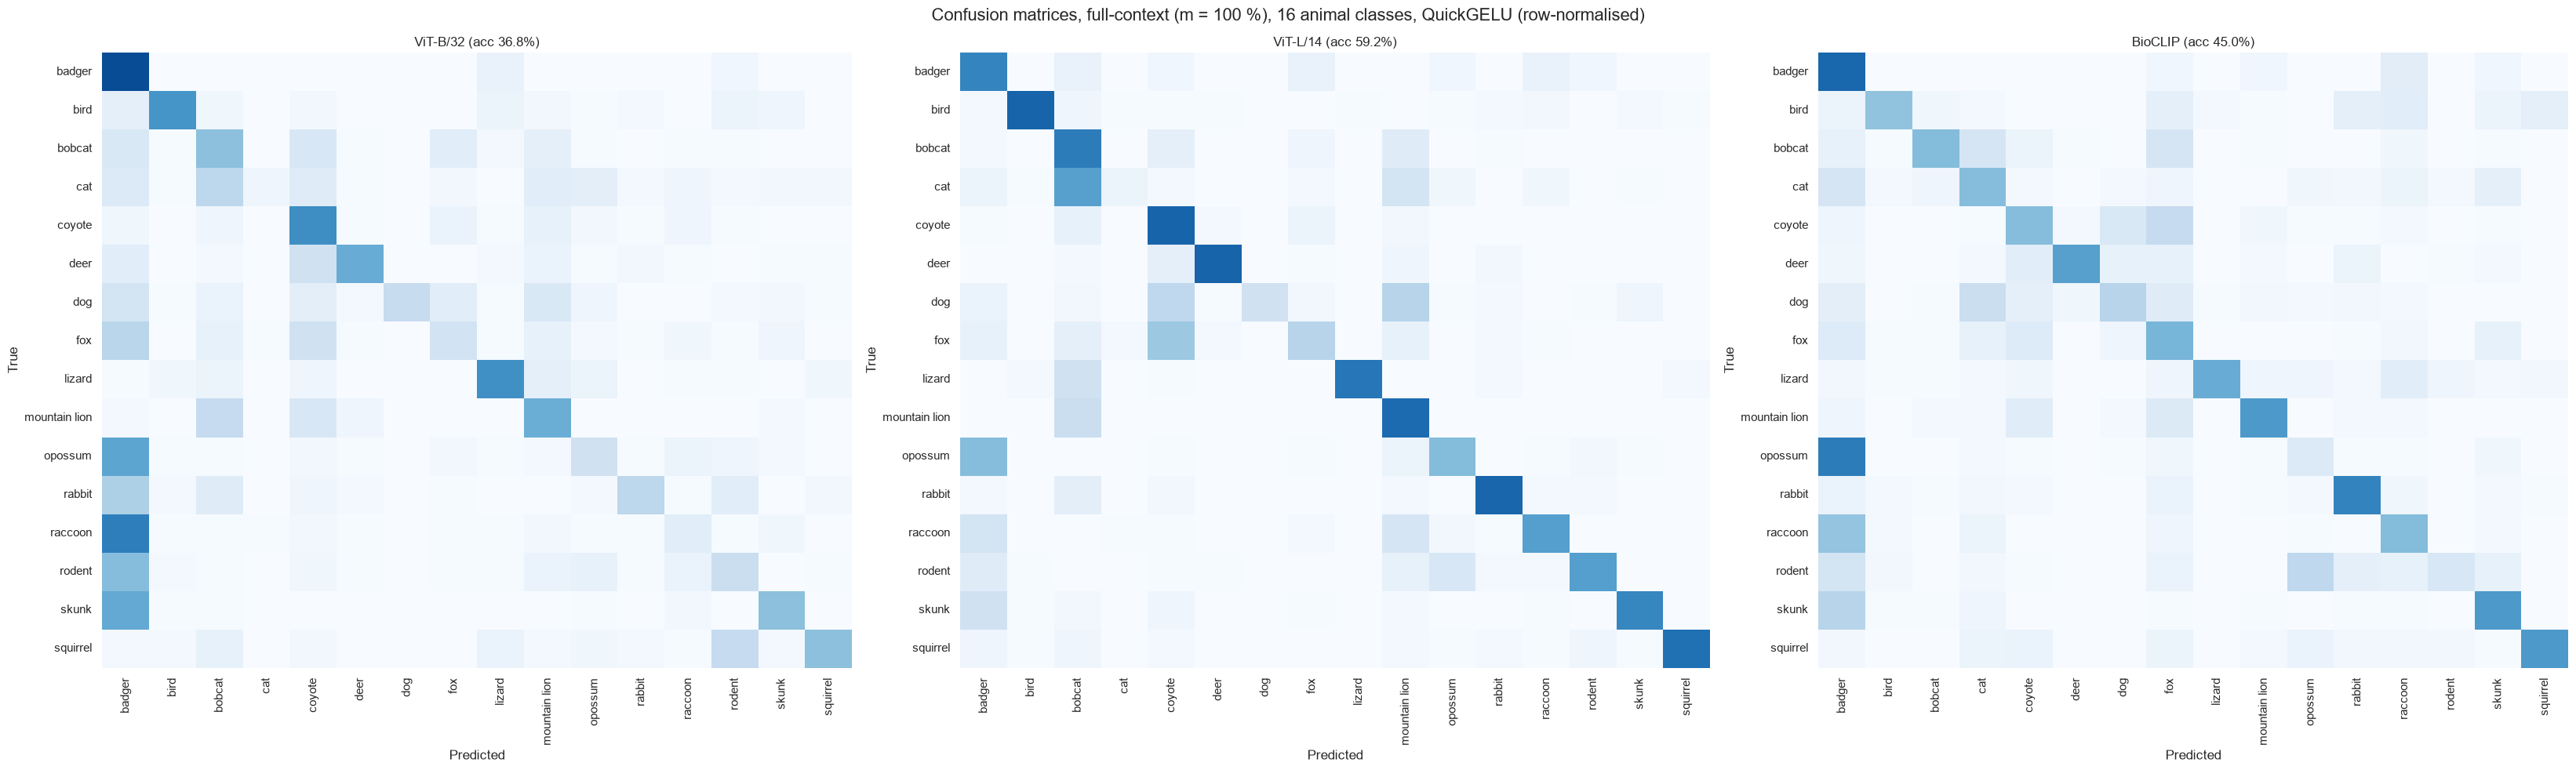

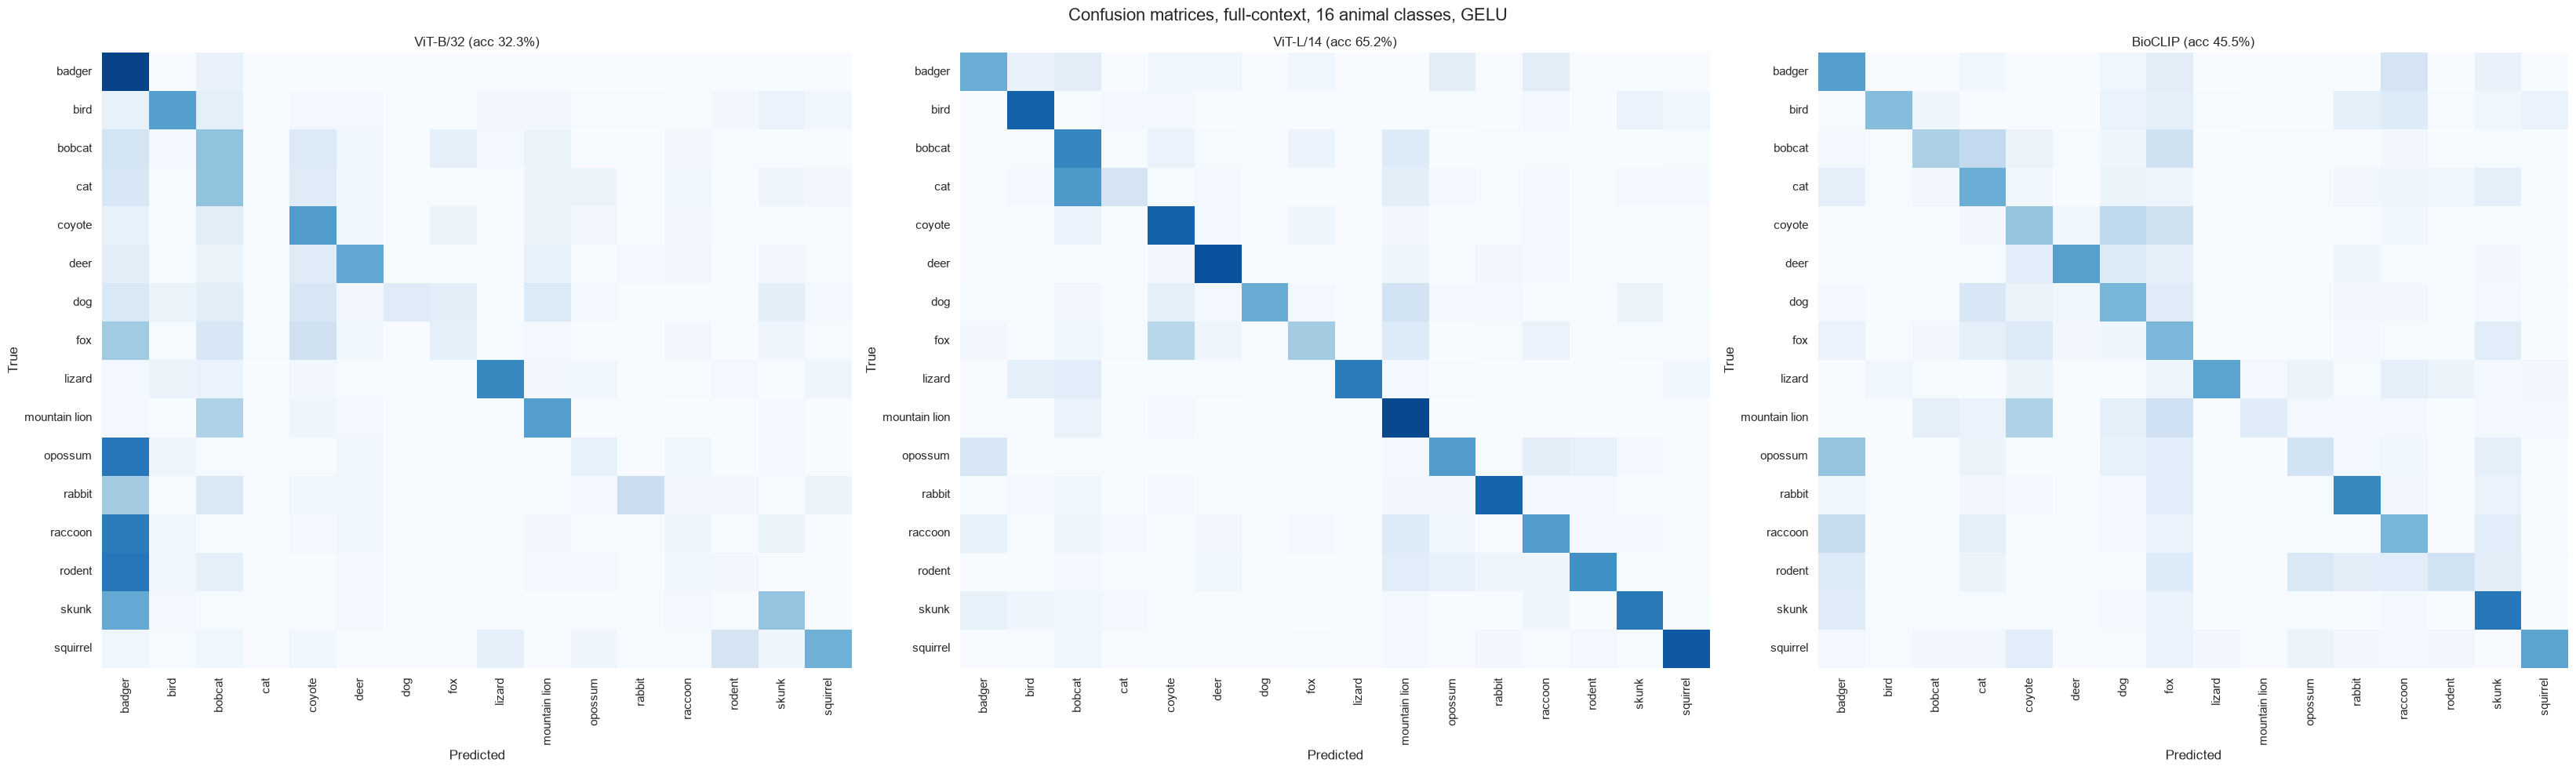

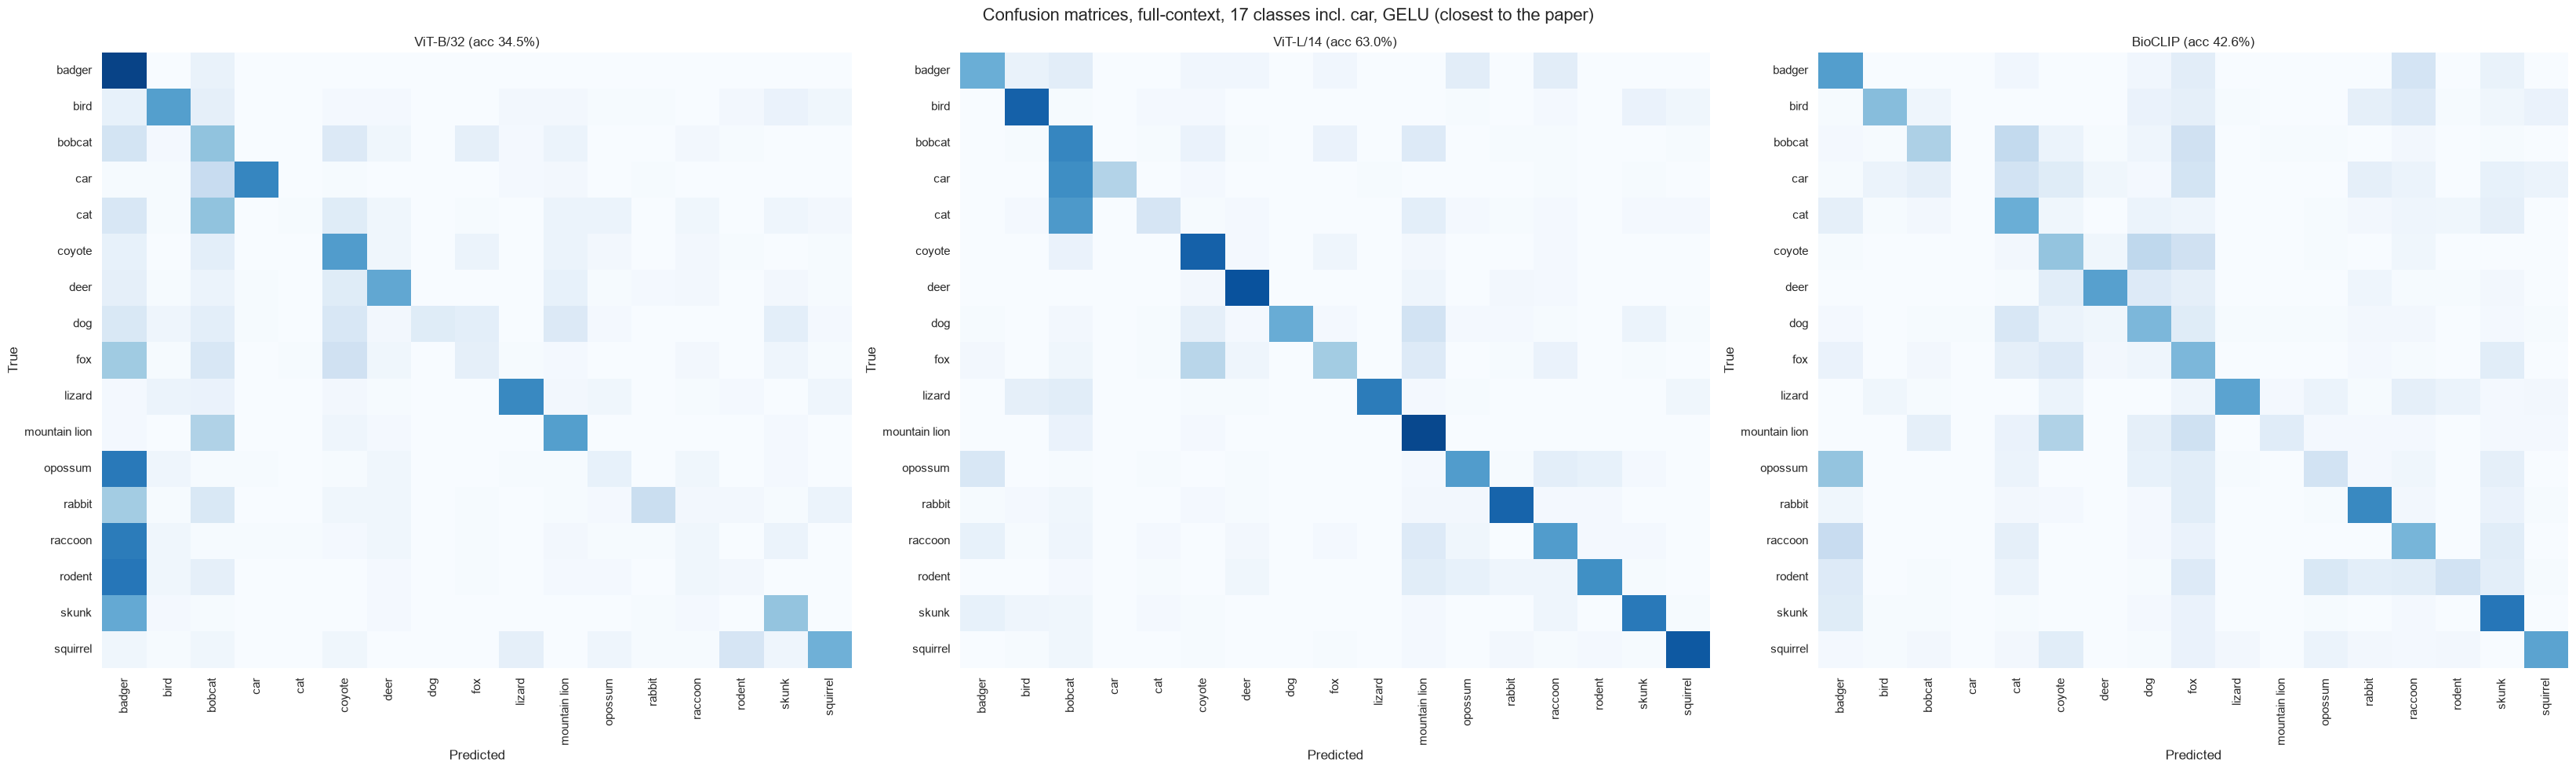

In [15]:
def conf_figs(run, exp, cond, fname, title):
    labs = sorted(RUNS[run].species.unique())
    fig, axs = plt.subplots(1, 3, figsize=(33, 10))
    for ax, m in zip(axs, MODELS):
        q = RUNS[run].query("model == @m and experiment == @exp and condition == @cond and prompt == 'neutral'")
        cm = confusion_matrix(q.species, q.prediction, labels=labs, normalize="true")
        sns.heatmap(cm, ax=ax, cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=[class_name(s) for s in labs], yticklabels=[class_name(s) for s in labs])
        ax.set_title(f"{m} (acc {100 * q.correct.mean():.1f}%)"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    fig.suptitle(title, fontsize=16); fig.tight_layout(); fig.savefig(FIG / fname, dpi=120); plt.show()
conf_figs("16c-Q", "exp1", "full", "fig_confusion_16cQ_full_context.png", "Confusion matrices, full-context (m = 100 %), 16 animal classes, QuickGELU (row-normalised)")
conf_figs("16c-G", "exp1", "full", "fig_confusion_16cG_full_context.png", "Confusion matrices, full-context, 16 animal classes, GELU")
conf_figs("17c-G", "exp1", "full", "fig_confusion_17cG_full_context.png", "Confusion matrices, full-context, 17 classes incl. car, GELU (closest to the paper)")

## 9. Hypotheses (JK Table 8), deployment guide (Table 9) and a claim-by-claim reproduction check
All verdicts are computed from the data (no manual editing).

In [16]:
def hyp(run):
    s, sp, pr = S(run), R[run]["species"], R[run]["prompts"].pivot(index="model", columns="prompt", values="acc")
    cd = s.CDS; out = {}
    out["H1: BioCLIP has lower CDS than general CLIP"] = (("Rejected" if cd["BioCLIP"] > max(cd["ViT-B/32"], cd["ViT-L/14"]) else "Supported" if cd["BioCLIP"] < min(cd["ViT-B/32"], cd["ViT-L/14"]) else "Mixed"),
        f"CDS B/32 {cd['ViT-B/32']:.1f}, L/14 {cd['ViT-L/14']:.1f}, BioCLIP {cd['BioCLIP']:.1f}")
    dog = sp[sp.species == "dog"].set_index("model").CDS; hi = sp[sp.species.isin(["opossum", "rodent"]) & (sp.model == "BioCLIP")].CDS
    out["H2: distinctive species are less context dependent"] = (("Partially supported" if (dog < 0).sum() >= 2 and hi.mean() > 50 else "Not supported"),
        f"dog CDS negative in {(dog < 0).sum()}/3 models; BioCLIP CDS opossum/rodent = {', '.join(f'{v:.0f}' for v in hi)}")
    out["H3: context removal degrades accuracy"] = (("Partially supported" if (cd > 0).any() and (cd < 0).any() else "Supported" if (cd > 0).all() else "Rejected"),
        "CDS > 0 (degrades): " + ", ".join(m for m in MODELS if cd[m] > 0) + " | CDS < 0 (improves): " + (", ".join(m for m in MODELS if cd[m] < 0) or "none"))
    dh = (pr["habitat"] - pr["neutral"]).round(1); dw = (pr["wildlife"] - pr["neutral"]).round(1)
    out["H4: habitat prompts increase context dependency"] = (("Mixed" if (dh > 0).any() and (dh < 0).any() else "Supported" if (dh > 0).all() else "Rejected"),
        "habitat-neutral (pp): " + ", ".join(f"{m} {dh[m]:+.1f}" for m in MODELS) + " | wildlife-neutral: " + ", ".join(f"{m} {dw[m]:+.1f}" for m in MODELS))
    return out
H = {r: hyp(r) for r in ("16c-Q", "16c-G", "17c-G")}
t8 = pd.DataFrame({"hypothesis": list(H["16c-Q"]), "paper_verdict": ["Rejected", "Partially supported", "Partially supported", "Mixed"],
                   **{f"{r} verdict": [v[0] for v in H[r].values()] for r in H}, "evidence (16c-Q)": [v[1] for v in H["16c-Q"].values()]}).set_index("hypothesis")
display(t8); save("table08_hypotheses", t8)

,paper_verdict,16c-Q verdict,16c-G verdict,17c-G verdict,evidence (16c-Q)
hypothesis,,,,,
H1: BioCLIP has lower CDS than general CLIP,Rejected,Rejected,Rejected,Rejected,"CDS B/32 -3.9, L/14 9.1, BioCLIP 31.2"
H2: distinctive species are less context dependent,Partially supported,Partially supported,Partially supported,Partially supported,dog CDS negative in 3/3 models; BioCLIP CDS op...
H3: context removal degrades accuracy,Partially supported,Partially supported,Partially supported,Partially supported,"CDS > 0 (degrades): ViT-L/14, BioCLIP | CDS < ..."
H4: habitat prompts increase context dependency,Mixed,Mixed,Mixed,Mixed,"habitat-neutral (pp): ViT-B/32 +2.2, ViT-L/14 ..."


,paper_verdict,16c-Q verdict,16c-G verdict,17c-G verdict,evidence (16c-Q)
hypothesis,,,,,
H1: BioCLIP has lower CDS than general CLIP,Rejected,Rejected,Rejected,Rejected,"CDS B/32 -3.9, L/14 9.1, BioCLIP 31.2"
H2: distinctive species are less context dependent,Partially supported,Partially supported,Partially supported,Partially supported,dog CDS negative in 3/3 models; BioCLIP CDS op...
H3: context removal degrades accuracy,Partially supported,Partially supported,Partially supported,Partially supported,"CDS > 0 (degrades): ViT-L/14, BioCLIP | CDS < ..."
H4: habitat prompts increase context dependency,Mixed,Mixed,Mixed,Mixed,"habitat-neutral (pp): ViT-B/32 +2.2, ViT-L/14 ..."


In [17]:
s, pr = S(PRIMARY), R[PRIMARY]["prompts"]
best = pr.loc[pr.acc.idxmax()]; sUT = s.loc["ViT-B/32"]
rob = s.CR
t9 = pd.DataFrame([
    dict(scenario="Highest accuracy (fixed habitats)", recommendation=f"{best.model} with the '{best.prompt}' prompt ({best.acc:.1f} % on original images)"),
    dict(scenario="Novel / changing habitats", recommendation=f"{rob.idxmax()} (highest Context Robustness, CR = {rob.max():.0f} %); BioCLIP lowest at CR = {rob['BioCLIP']:.0f} %"),
    dict(scenario="Limited compute", recommendation=f"ViT-B/32 with bbox pre-processing: ultra-tight {sUT.acc_ultra_tight:.1f} % vs full {sUT.acc_full:.1f} % (CDS {sUT.CDS:+.1f} %)"),
    dict(scenario="Avoid", recommendation=f"{s.CR.idxmin()} outside its training habitats (CR {s.CR.min():.0f} %, confidence-accuracy gap at UT {s.loc[s.CR.idxmin(), 'conf_acc_gap_ut']:.1f} pp)")])
display(t9.style.hide(axis="index")); save("table09_deployment_guide_primary", t9, index=False)

scenario,recommendation
Highest accuracy (fixed habitats),ViT-L/14 with the 'wildlife' prompt (45.2 % on original images)
Novel / changing habitats,"ViT-B/32 (highest Context Robustness, CR = 111 %); BioCLIP lowest at CR = 44 %"
Limited compute,ViT-B/32 with bbox pre-processing: ultra-tight 38.2 % vs full 36.8 % (CDS -3.9 %)
Avoid,"BioCLIP outside its training habitats (CR 44 %, confidence-accuracy gap at UT 37.9 pp)"


,scenario,recommendation
0,Highest accuracy (fixed habitats),ViT-L/14 with the 'wildlife' prompt (45.2 % on...
1,Novel / changing habitats,"ViT-B/32 (highest Context Robustness, CR = 111..."
2,Limited compute,ViT-B/32 with bbox pre-processing: ultra-tight...
3,Avoid,BioCLIP outside its training habitats (CR 44 %...


In [18]:
CL = []
def claim(text, paper_txt, fn): CL.append((text, paper_txt, fn))
def lv(r, m): q = R[r]["levels"].query("model == @m").set_index("level").acc; return q
claim("BioCLIP has the highest CDS", "37.0 %, highest", lambda r: (S(r).CDS.idxmax() == "BioCLIP", S(r).CDS.round(1).to_dict()))
claim("ViT-B/32 has a negative CDS", "-4.0 %", lambda r: (S(r).loc["ViT-B/32", "CDS"] < 0, f"{S(r).loc['ViT-B/32', 'CDS']:.1f}"))
claim("ViT-L/14 has a moderate positive CDS", "13.4 %", lambda r: (0 < S(r).loc["ViT-L/14", "CDS"] < S(r).loc["BioCLIP", "CDS"], f"{S(r).loc['ViT-L/14', 'CDS']:.1f}"))
claim("ViT-L/14 has the highest full-context accuracy", "62.5 %", lambda r: (S(r).acc_full.idxmax() == "ViT-L/14", S(r).acc_full.round(1).to_dict()))
claim("ViT-B/32 accuracy is non-monotonic (peak at an intermediate crop, ultra-tight above full)", "peak 38.7 % at medium",
      lambda r: ((lv(r, "ViT-B/32").loc[["loose", "medium", "tight"]].max() > lv(r, "ViT-B/32")["full"]) and lv(r, "ViT-B/32")["ultra_tight"] > lv(r, "ViT-B/32")["full"], lv(r, "ViT-B/32").round(1).to_dict()))
claim("BioCLIP has the lowest Context Robustness (CR < 50 %)", "46.5 %", lambda r: (S(r).CR.idxmin() == "BioCLIP" and S(r).loc["BioCLIP", "CR"] < 50, S(r).CR.round(1).to_dict()))
claim("ViT-B/32 is the most robust to wrong backgrounds (highest CR)", "86.0 %", lambda r: (S(r).CR.idxmax() == "ViT-B/32", S(r).CR.round(1).to_dict()))
claim("Desert is the least disruptive habitat, urban/aquatic the most (majority of models)", "desert best, urban/aquatic worst",
      lambda r: (sum(R[r]["habitat"].query("model == @m").set_index("habitat").acc.idxmax() == "desert" for m in MODELS) >= 2,
                 {m: R[r]["habitat"].query("model == @m").set_index("habitat").acc.round(1).to_dict() for m in MODELS}))
claim("Wildlife prompt improves ViT-B/32 and ViT-L/14 over neutral", "+9.3 / +6.7 pp",
      lambda r: (all(R[r]["prompts"].query("model == @m").set_index("prompt").acc.pipe(lambda a: a["wildlife"] > a["neutral"]) for m in ("ViT-B/32", "ViT-L/14")),
                 {m: round(R[r]["prompts"].query("model == @m").set_index("prompt").acc.pipe(lambda a: a["wildlife"] - a["neutral"]), 1) for m in MODELS}))
claim("Wildlife prompt hurts BioCLIP", "-7.4 pp", lambda r: (R[r]["prompts"].query("model == 'BioCLIP'").set_index("prompt").acc.pipe(lambda a: a["wildlife"] < a["neutral"]),
      round(R[r]["prompts"].query("model == 'BioCLIP'").set_index("prompt").acc.pipe(lambda a: a["wildlife"] - a["neutral"]), 1)))
claim("'Scientific specimen' is the worst prompt for every model", "lowest for all", lambda r: (all(R[r]["prompts"].query("model == @m").set_index("prompt").acc.idxmin() == "scientific" for m in MODELS),
      {m: R[r]["prompts"].query("model == @m").set_index("prompt").acc.idxmin() for m in MODELS}))
claim("ViT-B/32 has the highest Prompt Sensitivity", "45.7 %", lambda r: (S(r).PS.idxmax() == "ViT-B/32", S(r).PS.round(1).to_dict()))
claim("ViT-L/14 is the most prompt-stable model", "25.2 %", lambda r: (S(r).PS.idxmin() == "ViT-L/14", S(r).PS.round(1).to_dict()))
claim("BioCLIP has the largest confidence-accuracy gap at ultra-tight crops", "41.3 pp", lambda r: (S(r).conf_acc_gap_ut.idxmax() == "BioCLIP", S(r).conf_acc_gap_ut.round(1).to_dict()))
claim("All models exceed chance on background-only images", "11.8-16.5 % vs 5.9 %", lambda r: ((S(r).BG_only > 100 / S(r).n_species.iloc[0]).all(), S(r).BG_only.round(1).to_dict()))
claim("Dog has a negative CDS for all three models", "all negative", lambda r: ((R[r]["species"].query("species == 'dog'").CDS < 0).all(), R[r]["species"].query("species == 'dog'").set_index("model").CDS.round(1).to_dict()))
claim("BioCLIP drops to 0 % for opossum and rodent without context", "0 % / 0 %", lambda r: ((R[r]["species"].query("model == 'BioCLIP' and species in ['opossum', 'rodent']").acc_ultra_tight == 0).all(),
      R[r]["species"].query("model == 'BioCLIP' and species in ['opossum', 'rodent']").set_index("species").acc_ultra_tight.round(1).to_dict()))
claim("ViT-B/32 has a negative CDS for ~half of the species (paper: 9 of 17)", "9 / 17", lambda r: (S(r).loc["ViT-B/32", "neg_cds_species"] >= 7, f"{S(r).loc['ViT-B/32', 'neg_cds_species']} of {S(r).loc['ViT-B/32', 'n_species']}"))
def car_claim(r):
    sp = R[r]["species"].query("species == 'car'")
    return ("n/a (no car)", "car removed") if sp.empty else (bool((sp.CDS == 0).all()), sp.set_index("model").CDS.round(1).to_dict())
claim("Car CDS = 0 for every model ('validates the method')", "0 / 0 / 0", car_claim)
RUNS_C = ["16c-Q", "16c-G", "17c-G", "17c-Q"]
rows = []
for text, ptxt, fn in CL:
    row = {"claim": text, "paper": ptxt}
    for r in RUNS_C:
        ok, ev = fn(r); row[r] = ok if isinstance(ok, str) else ("YES" if ok else "no"); row[f"evidence {r}"] = ev
    rows.append(row)
claims = pd.DataFrame(rows).set_index("claim"); save("claims_reproduction_check", claims)
display(claims[["paper"] + RUNS_C].style.map(lambda v: "background-color:#c7e9c0" if v == "YES" else "background-color:#fcbba1" if v == "no" else "").set_properties(**{"text-align": "left"}))
print("claims reproduced (YES) per run:", {r: int((claims[r] == "YES").sum()) for r in RUNS_C}, "of", len(claims))
display(claims[["evidence 16c-Q", "evidence 17c-G"]])

,paper,16c-Q,16c-G,17c-G,17c-Q
claim,,,,,
BioCLIP has the highest CDS,"37.0 %, highest",YES,YES,YES,YES
ViT-B/32 has a negative CDS,-4.0 %,YES,YES,YES,YES
ViT-L/14 has a moderate positive CDS,13.4 %,YES,YES,YES,YES
ViT-L/14 has the highest full-context accuracy,62.5 %,YES,YES,YES,YES
"ViT-B/32 accuracy is non-monotonic (peak at an intermediate crop, ultra-tight above full)",peak 38.7 % at medium,YES,YES,YES,YES
BioCLIP has the lowest Context Robustness (CR < 50 %),46.5 %,YES,YES,YES,YES
ViT-B/32 is the most robust to wrong backgrounds (highest CR),86.0 %,YES,YES,YES,YES
"Desert is the least disruptive habitat, urban/aquatic the most (majority of models)","desert best, urban/aquatic worst",no,no,no,no
Wildlife prompt improves ViT-B/32 and ViT-L/14 over neutral,+9.3 / +6.7 pp,YES,YES,YES,YES


claims reproduced (YES) per run: {'16c-Q': 15, '16c-G': 13, '17c-G': 14, '17c-Q': 14} of 19


,evidence 16c-Q,evidence 17c-G
claim,,
BioCLIP has the highest CDS,"{'ViT-B/32': -3.9, 'ViT-L/14': 9.1, 'BioCLIP':...","{'ViT-B/32': -6.1, 'ViT-L/14': 11.5, 'BioCLIP'..."
ViT-B/32 has a negative CDS,-3.9,-6.1
ViT-L/14 has a moderate positive CDS,9.1,11.5
ViT-L/14 has the highest full-context accuracy,"{'ViT-B/32': 36.8, 'ViT-L/14': 59.2, 'BioCLIP'...","{'ViT-B/32': 34.5, 'ViT-L/14': 63.0, 'BioCLIP'..."
"ViT-B/32 accuracy is non-monotonic (peak at an intermediate crop, ultra-tight above full)","{'full': 36.8, 'loose': 41.7, 'medium': 42.3, ...","{'full': 34.5, 'loose': 38.7, 'medium': 38.9, ..."
BioCLIP has the lowest Context Robustness (CR < 50 %),"{'ViT-B/32': 110.8, 'ViT-L/14': 84.9, 'BioCLIP...","{'ViT-B/32': 104.5, 'ViT-L/14': 78.1, 'BioCLIP..."
ViT-B/32 is the most robust to wrong backgrounds (highest CR),"{'ViT-B/32': 110.8, 'ViT-L/14': 84.9, 'BioCLIP...","{'ViT-B/32': 104.5, 'ViT-L/14': 78.1, 'BioCLIP..."
"Desert is the least disruptive habitat, urban/aquatic the most (majority of models)","{'ViT-B/32': {'arctic': 16.9, 'desert': 12.4, ...","{'ViT-B/32': {'arctic': 17.3, 'desert': 15.5, ..."
Wildlife prompt improves ViT-B/32 and ViT-L/14 over neutral,"{'ViT-B/32': 11.5, 'ViT-L/14': 9.4, 'BioCLIP':...","{'ViT-B/32': 7.6, 'ViT-L/14': 7.2, 'BioCLIP': ..."


## 10. EDA on the results (what drives the errors?)
Uses the per-image predictions of the primary run joined with the sample metadata (box size, night/IR frames, camera, hour).

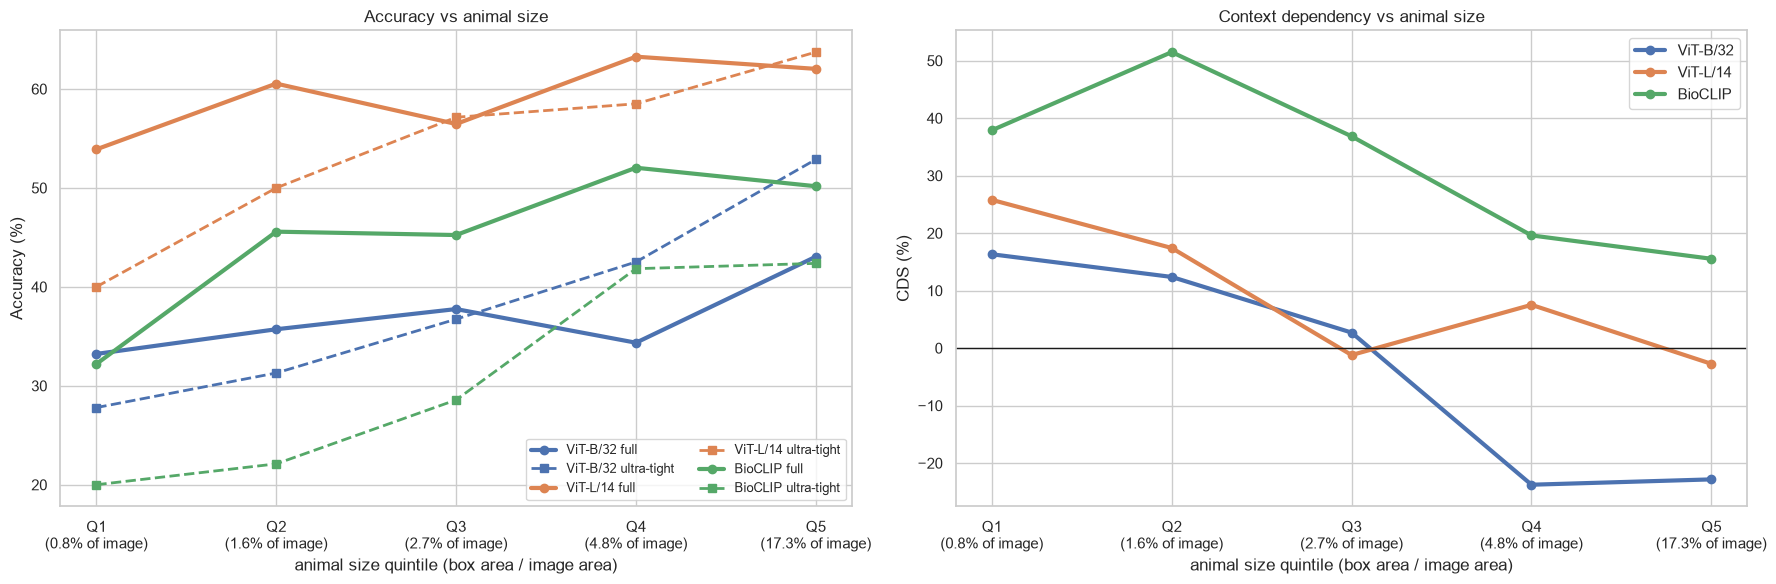

,model,size_bin,median_box_frac,acc_full,acc_ut,CDS
0,ViT-B/32,Q1,0.01,33.22,27.80,16.33
1,ViT-B/32,Q2,0.02,35.71,31.29,12.38
2,ViT-B/32,Q3,0.03,37.76,36.73,2.70
3,ViT-B/32,Q4,0.05,34.35,42.52,-23.76
4,ViT-B/32,Q5,0.17,43.05,52.88,-22.83
5,ViT-L/14,Q1,0.01,53.90,40.00,25.79
6,ViT-L/14,Q2,0.02,60.54,50.00,17.42
7,ViT-L/14,Q3,0.03,56.46,57.14,-1.20
8,ViT-L/14,Q4,0.05,63.27,58.50,7.53
9,ViT-L/14,Q5,0.17,62.03,63.73,-2.73


In [19]:
E = RUNS[PRIMARY]
def per_sample(exp, cond, m): return E.query("model == @m and experiment == @exp and condition == @cond and prompt == 'neutral'")[["sample_id", "correct", "confidence", "prediction", "species"]]
meta_cols = ["sample_id", "box_frac", "is_gray_ir", "brightness", "hour", "location"]
full = {m: per_sample("exp1", "full", m).merge(S16[meta_cols], on="sample_id") for m in MODELS}
ut = {m: per_sample("exp1", "ultra_tight", m).merge(S16[meta_cols], on="sample_id") for m in MODELS}
# (a) accuracy vs animal size
S16["size_bin"] = pd.qcut(S16.box_frac, 5, labels=[f"Q{i + 1}" for i in range(5)])
medf = S16.groupby("size_bin").box_frac.median()
fig, axs = plt.subplots(1, 2, figsize=(18, 6))
rows = []
for m in MODELS:
    f_, u_ = full[m].merge(S16[["sample_id", "size_bin"]], on="sample_id"), ut[m].merge(S16[["sample_id", "size_bin"]], on="sample_id")
    af, au = f_.groupby("size_bin").correct.mean() * 100, u_.groupby("size_bin").correct.mean() * 100
    axs[0].plot(range(5), af, "o-", color=MODEL_COLORS[m], lw=3, label=f"{m} full"); axs[0].plot(range(5), au, "s--", color=MODEL_COLORS[m], lw=2, label=f"{m} ultra-tight")
    for b in af.index: rows.append(dict(model=m, size_bin=b, median_box_frac=medf[b], acc_full=af[b], acc_ut=au[b], CDS=cds(af[b], au[b])))
    axs[1].plot(range(5), [cds(af[b], au[b]) for b in af.index], "o-", color=MODEL_COLORS[m], lw=3, label=m)
for ax in axs: ax.set_xticks(range(5)); ax.set_xticklabels([f"{b}\n({100 * medf[b]:.1f}% of image)" for b in medf.index]); ax.set_xlabel("animal size quintile (box area / image area)")
axs[0].set_ylabel("Accuracy (%)"); axs[0].set_title("Accuracy vs animal size"); axs[1].axhline(0, color="k", lw=1); axs[1].set_ylabel("CDS (%)"); axs[1].set_title("Context dependency vs animal size")
axs[0].legend(ncol=2, fontsize=9); axs[1].legend(); fig.tight_layout(); fig.savefig(FIG / "eda_accuracy_cds_vs_animal_size.png", dpi=160); plt.show()
save("eda_size_bins", pd.DataFrame(rows).round(2), index=False)

,model,frames,n,acc_full,acc_ut,CDS
0,ViT-B/32,colour (day),632,51.9,61.1,-17.7
1,ViT-B/32,grayscale / IR (night),840,25.5,21.1,17.3
2,ViT-L/14,colour (day),632,69.1,74.2,-7.3
3,ViT-L/14,grayscale / IR (night),840,51.8,38.6,25.5
4,BioCLIP,colour (day),632,54.9,44.5,19.0
5,BioCLIP,grayscale / IR (night),840,37.6,20.8,44.6


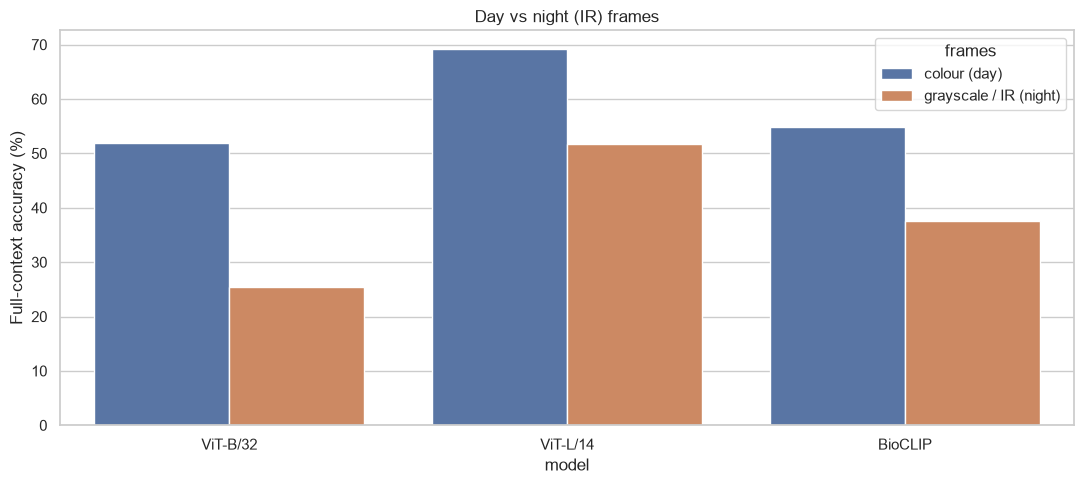

prediction         badger  bobcat  cat  coyote  fox  mountain_lion  opossum  \
model    species                                                              
BioCLIP  cat           17       0    0       0    0              0        0   
         coyote         0       0    0       0   25              0        0   
         dog            0       0   23       0    0              0        0   
         opossum       71       0    0       0    0              0        0   
         raccoon       40       0    0       0    0              0        0   
         rodent        18       0    0       0    0              0       27   
         skunk         30       0    0       0    0              0        0   
ViT-B/32 cat            0      28    0       0    0              0        0   
         fox           29       0    0       0    0              0        0   
         opossum       54       0    0       0    0              0        0   
         rabbit        33       0    0       0    0              0        0   
         raccoon       70       0    0       0    0              0        0   
         rodent        43       0    0       0    0              0        0   
         skunk         52       0    0       0    0              0        0   
         squirrel       0       0    0       0    0              0        0   
ViT-L/14 cat            0      56    0       0    0             18        0   
         dog            0       0    0      27    0             30        0   
         fox            0       0    0      38    0              0        0   
         lizard         0      20    0       0    0              0        0   
         opossum       43       0    0       0    0              0        0   
         skunk         20       0    0       0    0              0        0   

prediction         rodent  
model    species           
BioCLIP  cat            0  
         coyote         0  
         dog            0  
         opossum        0  
         raccoon        0  
         rodent         0  
         skunk          0  
ViT-B/32 cat            0  
         fox            0  
         opossum        0  
         rabbit         0  
         raccoon        0  
         rodent         0  
         skunk          0  
         squirrel      25  
ViT-L/14 cat            0  
         dog            0  
         fox            0  
         lizard         0  
         opossum        0  
         skunk          0

,species,prediction,count,model
0,raccoon,badger,70,ViT-B/32
1,opossum,badger,54,ViT-B/32
2,skunk,badger,52,ViT-B/32
3,rodent,badger,43,ViT-B/32
4,rabbit,badger,33,ViT-B/32
5,fox,badger,29,ViT-B/32
6,cat,bobcat,28,ViT-B/32
7,squirrel,rodent,25,ViT-B/32
0,cat,bobcat,56,ViT-L/14
1,opossum,badger,43,ViT-L/14


In [20]:
# (b) day vs night (grayscale = infrared frames)
rows = []
for m in MODELS:
    for g, name in ((False, "colour (day)"), (True, "grayscale / IR (night)")):
        f_, u_ = full[m][full[m].is_gray_ir == g], ut[m][ut[m].is_gray_ir == g]
        rows.append(dict(model=m, frames=name, n=len(f_), acc_full=100 * f_.correct.mean(), acc_ut=100 * u_.correct.mean(), CDS=cds(100 * f_.correct.mean(), 100 * u_.correct.mean())))
dn = pd.DataFrame(rows); display(dn.round(1)); save("eda_day_vs_night", dn.round(2), index=False)
fig, ax = plt.subplots(figsize=(11, 5)); sns.barplot(data=dn, x="model", y="acc_full", hue="frames", ax=ax); ax.set_ylabel("Full-context accuracy (%)"); ax.set_title("Day vs night (IR) frames")
fig.tight_layout(); fig.savefig(FIG / "eda_day_vs_night.png", dpi=160); plt.show()
# (c) most frequent confusions at full context
tops = []
for m in MODELS:
    w = full[m][full[m].species != full[m].prediction]
    tops.append(w.groupby(["species", "prediction"]).size().sort_values(ascending=False).head(8).rename("count").reset_index().assign(model=m))
tops = pd.concat(tops); display(tops.pivot_table(index=["model", "species"], columns="prediction", values="count").dropna(how="all").fillna(0).astype(int))
save("eda_top_confusions", tops, index=False)

,model,context,accuracy,mean_conf,ECE
0,ViT-B/32,full,36.8,52.4,15.6
1,ViT-B/32,ultra-tight,38.2,49.0,10.8
2,ViT-L/14,full,59.2,71.6,12.4
3,ViT-L/14,ultra-tight,53.9,64.3,10.4
4,BioCLIP,full,45.0,76.6,31.5
5,BioCLIP,ultra-tight,31.0,68.9,37.9


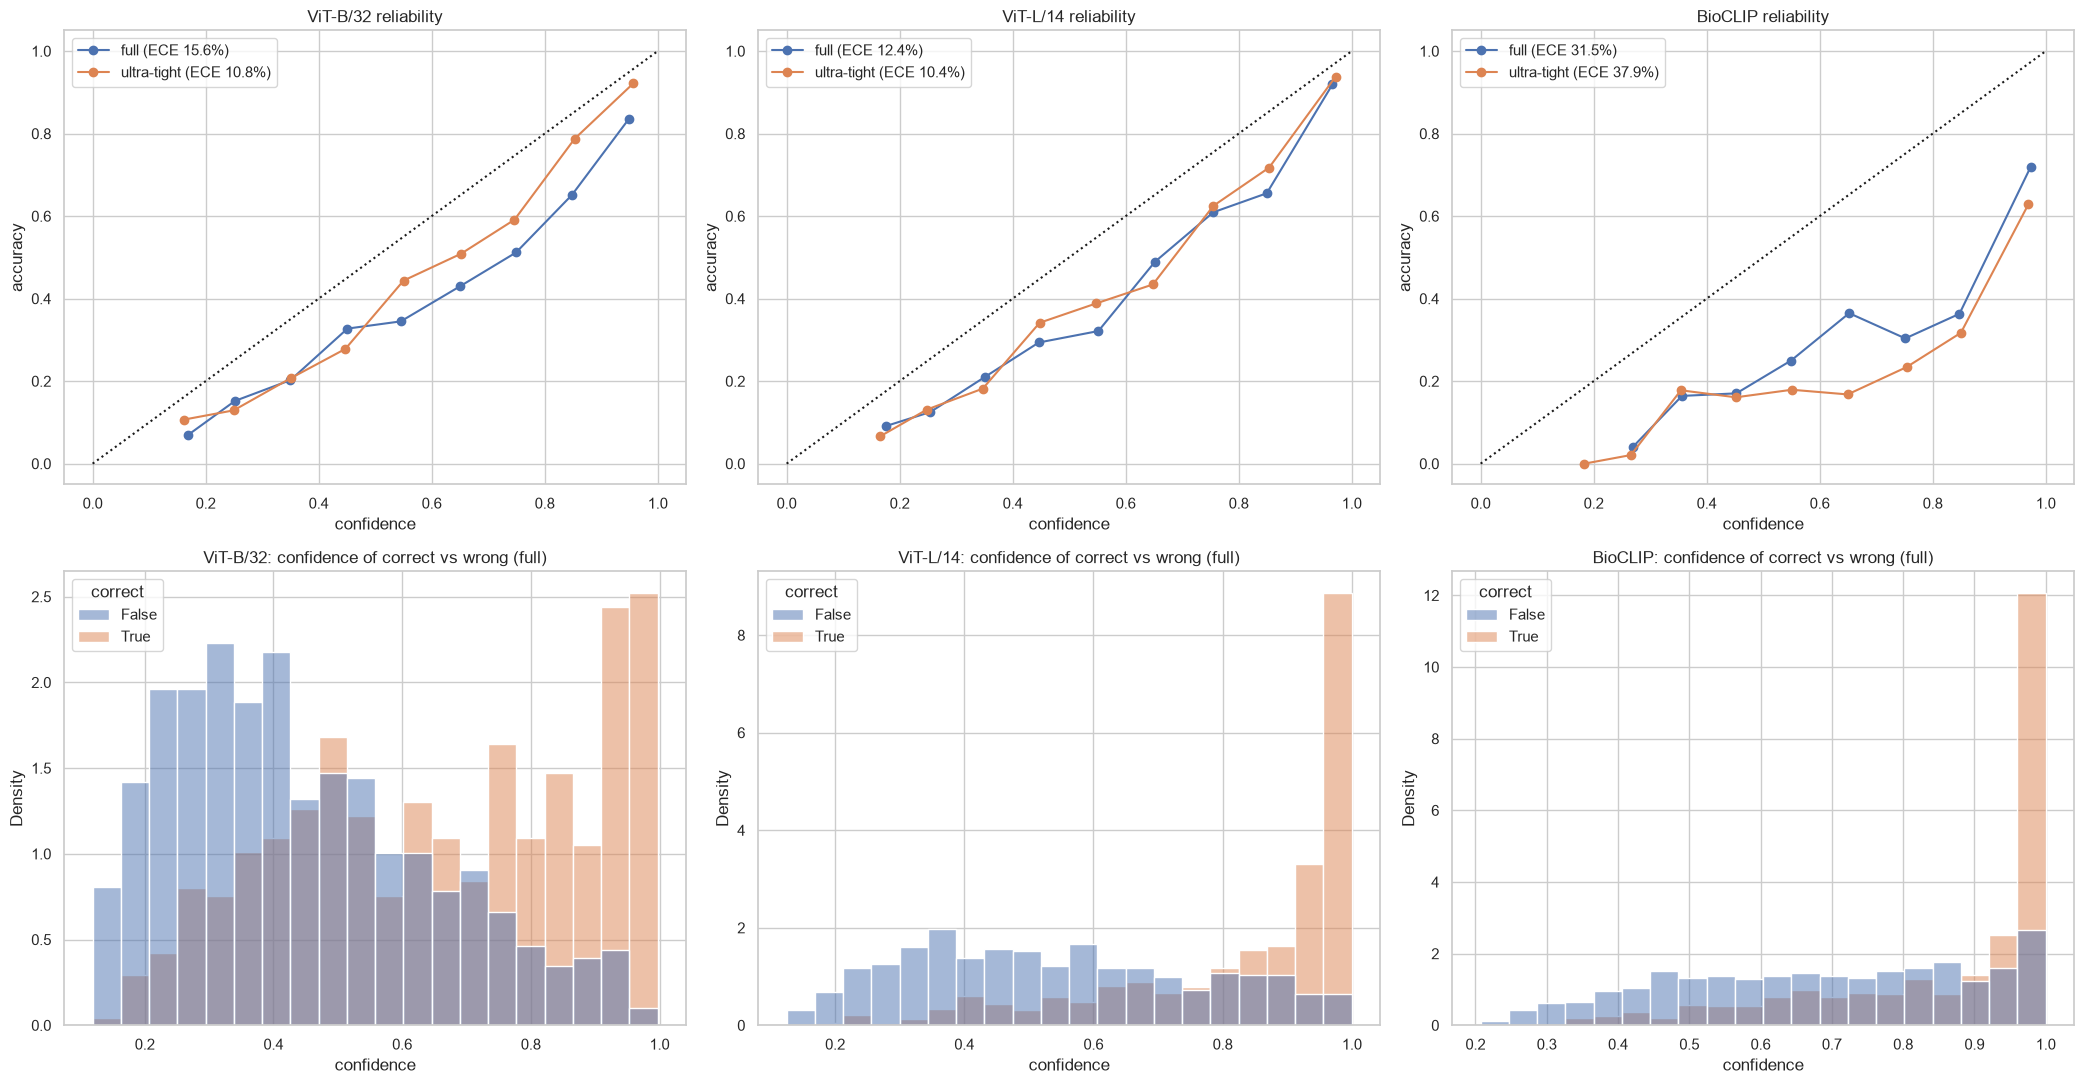

In [21]:
# (d) calibration: confidence of correct vs wrong predictions, reliability diagram and ECE
fig, axs = plt.subplots(2, 3, figsize=(21, 11)); rows = []
for j, m in enumerate(MODELS):
    for cond, dd in (("full", full[m]), ("ultra-tight", ut[m])):
        e, bins = ece(dd.confidence, dd.correct); rows.append(dict(model=m, context=cond, accuracy=100 * dd.correct.mean(), mean_conf=100 * dd.confidence.mean(), ECE=e))
        axs[0, j].plot([b[0] for b in bins], [b[1] for b in bins], "o-", label=f"{cond} (ECE {e:.1f}%)")
    axs[0, j].plot([0, 1], [0, 1], "k:"); axs[0, j].set_title(f"{m} reliability"); axs[0, j].set_xlabel("confidence"); axs[0, j].set_ylabel("accuracy"); axs[0, j].legend()
    sns.histplot(data=full[m], x="confidence", hue="correct", bins=20, stat="density", common_norm=False, ax=axs[1, j]); axs[1, j].set_title(f"{m}: confidence of correct vs wrong (full)")
cal = pd.DataFrame(rows); display(cal.round(1)); save("eda_calibration", cal.round(2), index=False)
fig.tight_layout(); fig.savefig(FIG / "eda_calibration.png", dpi=150); plt.show()

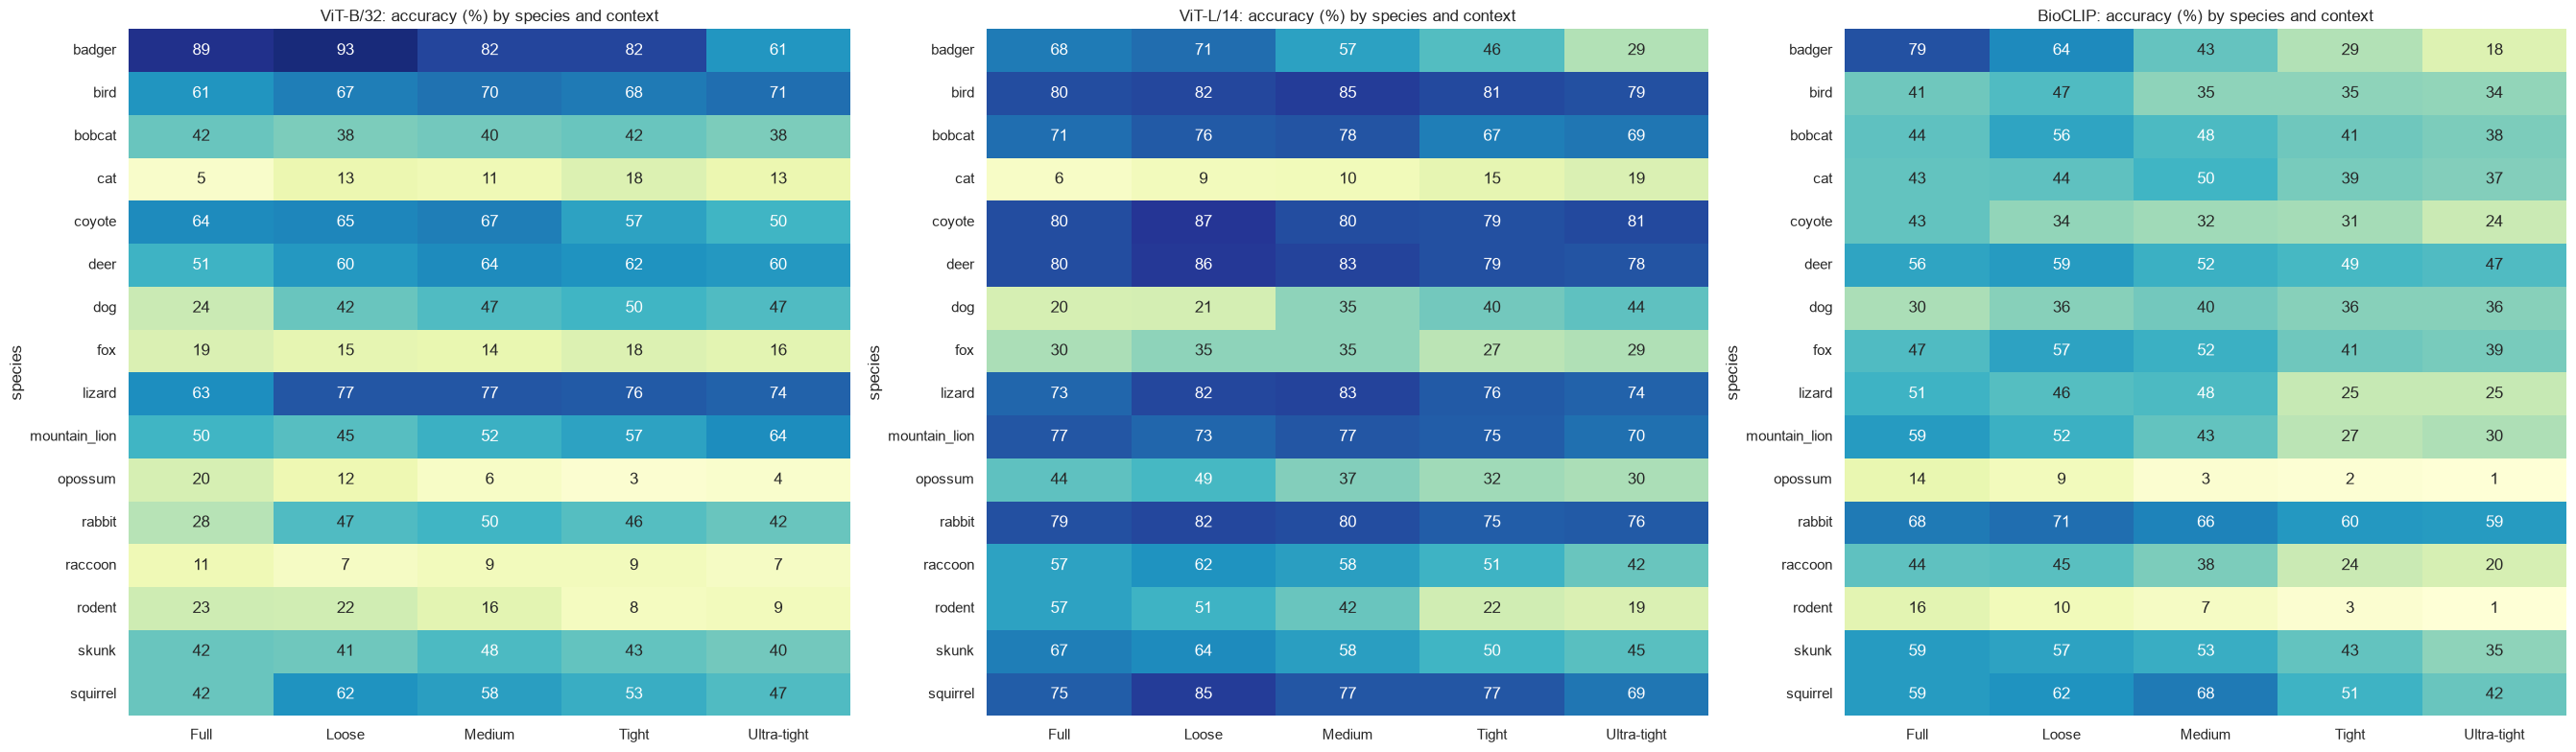

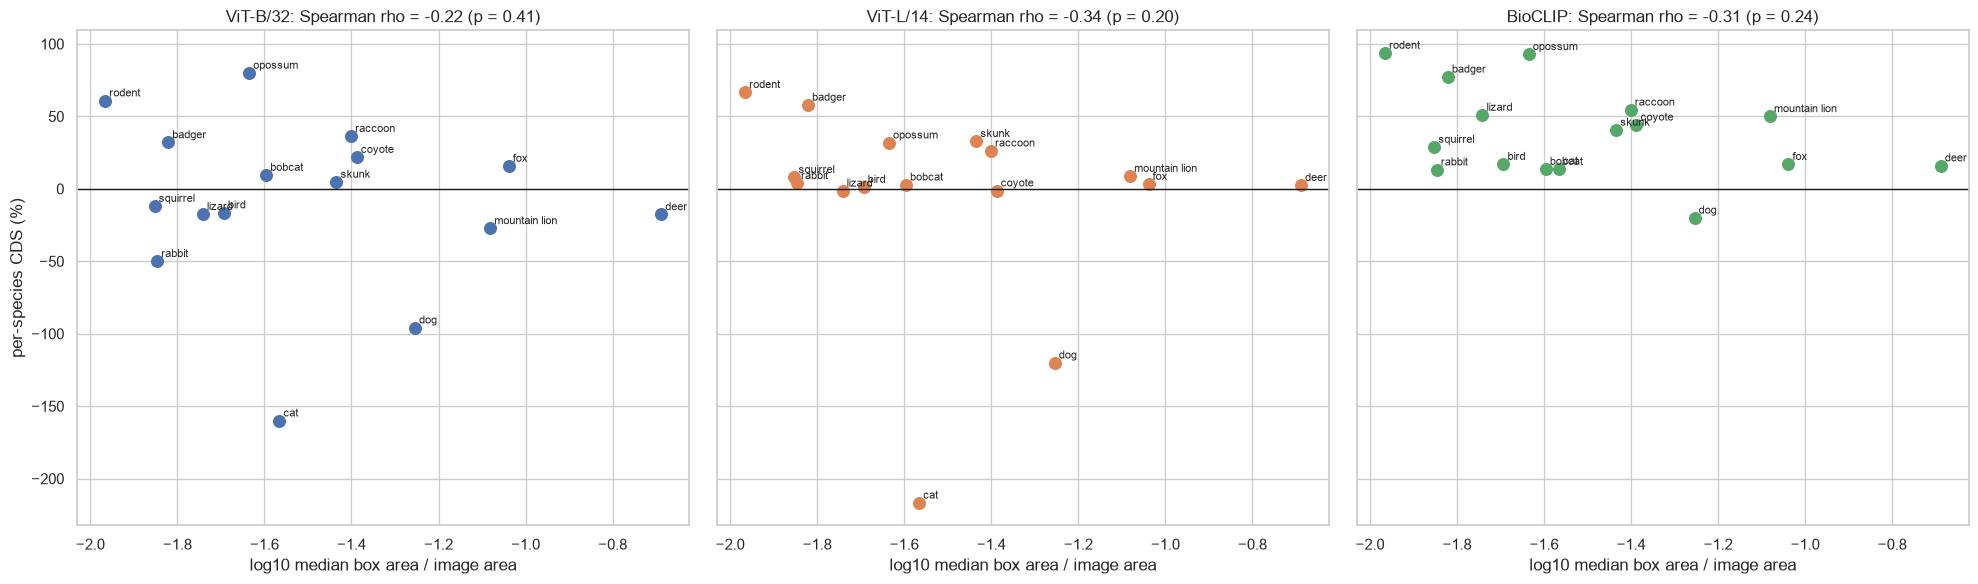

,model,spearman_rho,p_value
0,ViT-B/32,-0.224,0.405
1,ViT-L/14,-0.341,0.196
2,BioCLIP,-0.309,0.244


,model,spearman_rho,p_value
0,ViT-B/32,-0.2235,0.4053
1,ViT-L/14,-0.3412,0.1959
2,BioCLIP,-0.3088,0.2445


In [22]:
# (e) accuracy per species and context level (heat), (f) does CDS depend on animal size across species?
fig, axs = plt.subplots(1, 3, figsize=(27, 8))
for ax, m in zip(axs, MODELS):
    q = E.query("model == @m and experiment == 'exp1'").groupby(["species", "condition"]).correct.mean().mul(100).unstack()[LEVELS]
    q.columns = LEVEL_LABELS; sns.heatmap(q, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar=False, vmin=0, vmax=100); ax.set_title(f"{m}: accuracy (%) by species and context")
fig.tight_layout(); fig.savefig(FIG / "eda_species_by_level.png", dpi=140); plt.show()
bf = S16.groupby("species").box_frac.median()
fig, axs = plt.subplots(1, 3, figsize=(20, 6), sharey=True); rows = []
for ax, m in zip(axs, MODELS):
    sp = R[PRIMARY]["species"].query("model == @m").set_index("species"); x, y = np.log10(bf.reindex(sp.index)), sp.CDS
    rho, pv = spearmanr(x, y); rows.append(dict(model=m, spearman_rho=rho, p_value=pv))
    ax.scatter(x, y, color=MODEL_COLORS[m], s=70)
    for s_ in sp.index: ax.annotate(class_name(s_), (x[s_], y[s_]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, color="k", lw=1); ax.set_xlabel("log10 median box area / image area"); ax.set_title(f"{m}: Spearman rho = {rho:.2f} (p = {pv:.2f})")
axs[0].set_ylabel("per-species CDS (%)"); fig.tight_layout(); fig.savefig(FIG / "eda_cds_vs_animal_size_per_species.png", dpi=150); plt.show()
display(pd.DataFrame(rows).round(3)); save("eda_cds_size_correlation", pd.DataFrame(rows).round(4), index=False)

## 11. Qualitative example panels (paper's qualitative figure)
First sample of each species in the sample list (not cherry-picked). Predictions are those of the three models in the stated run.

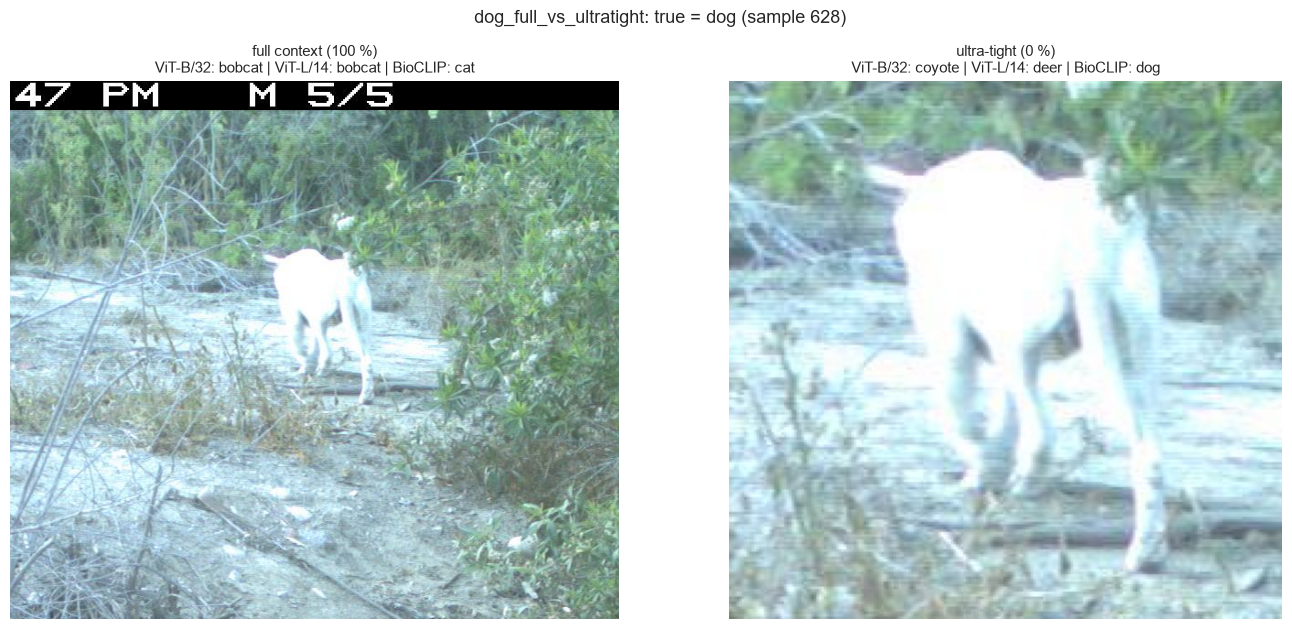

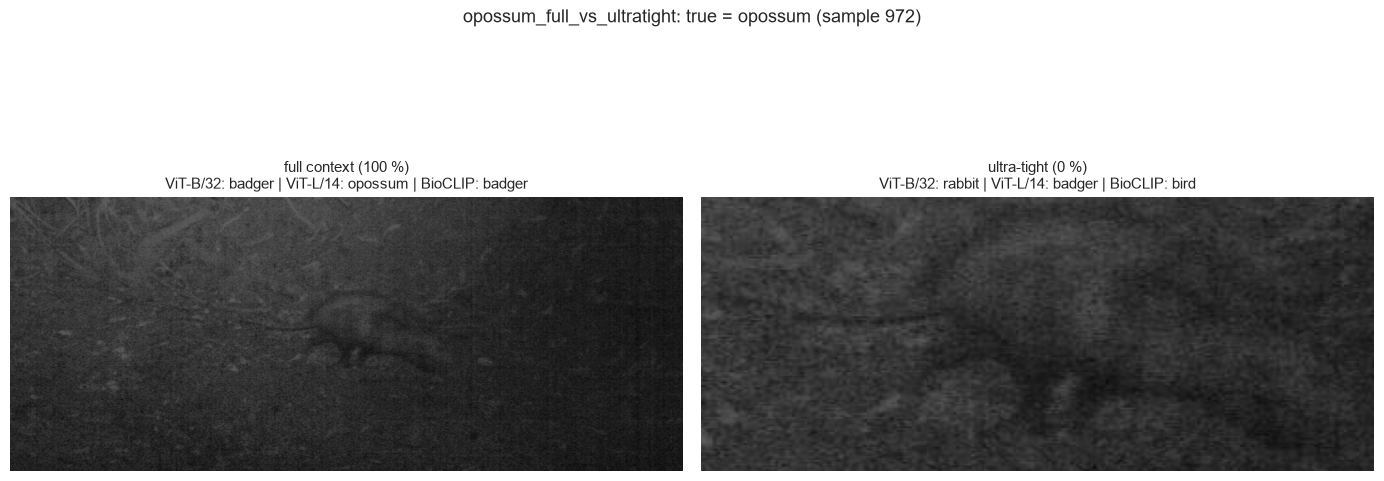

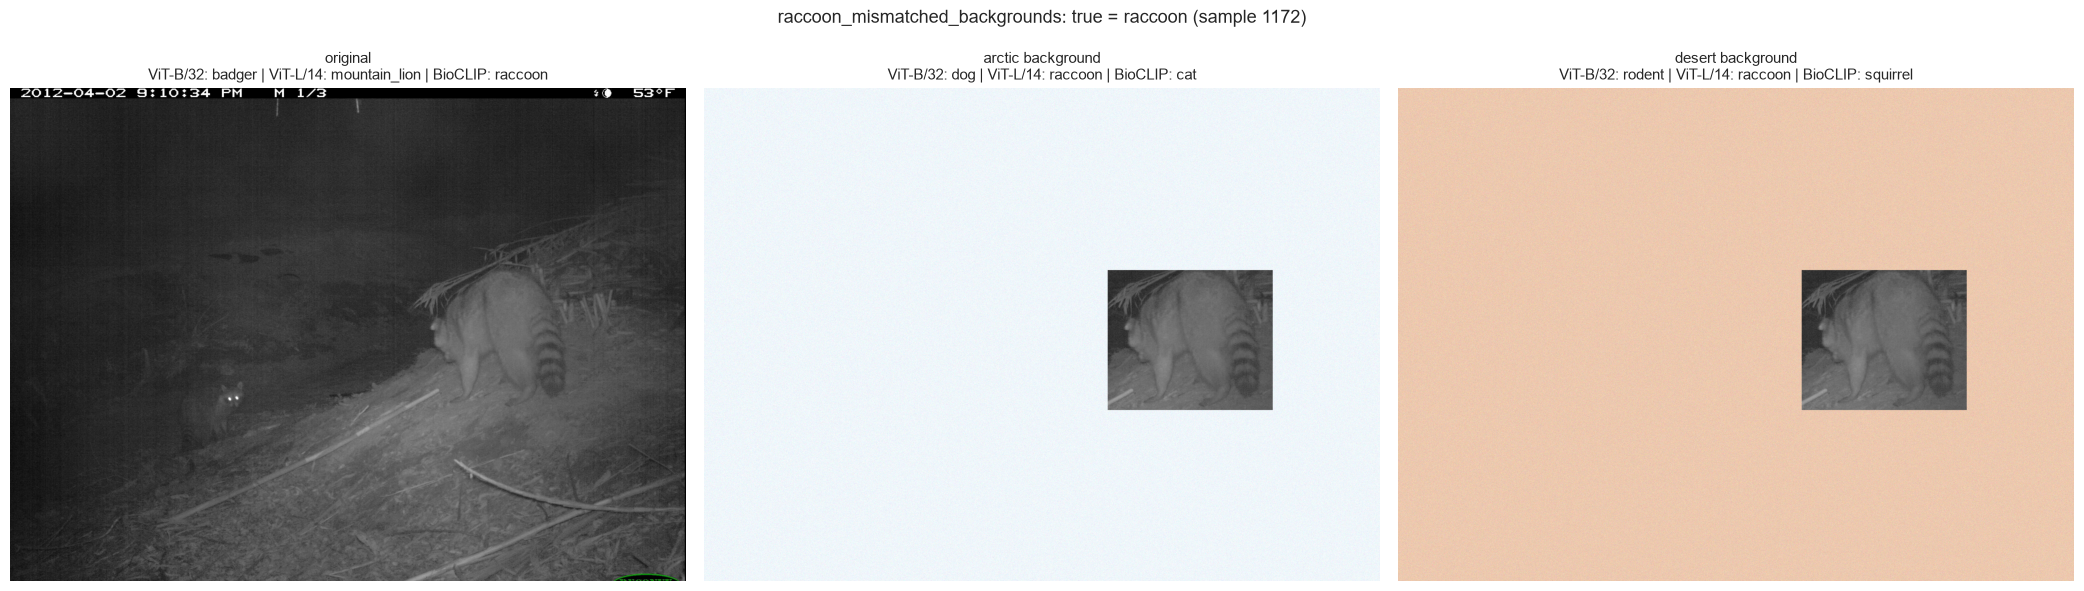

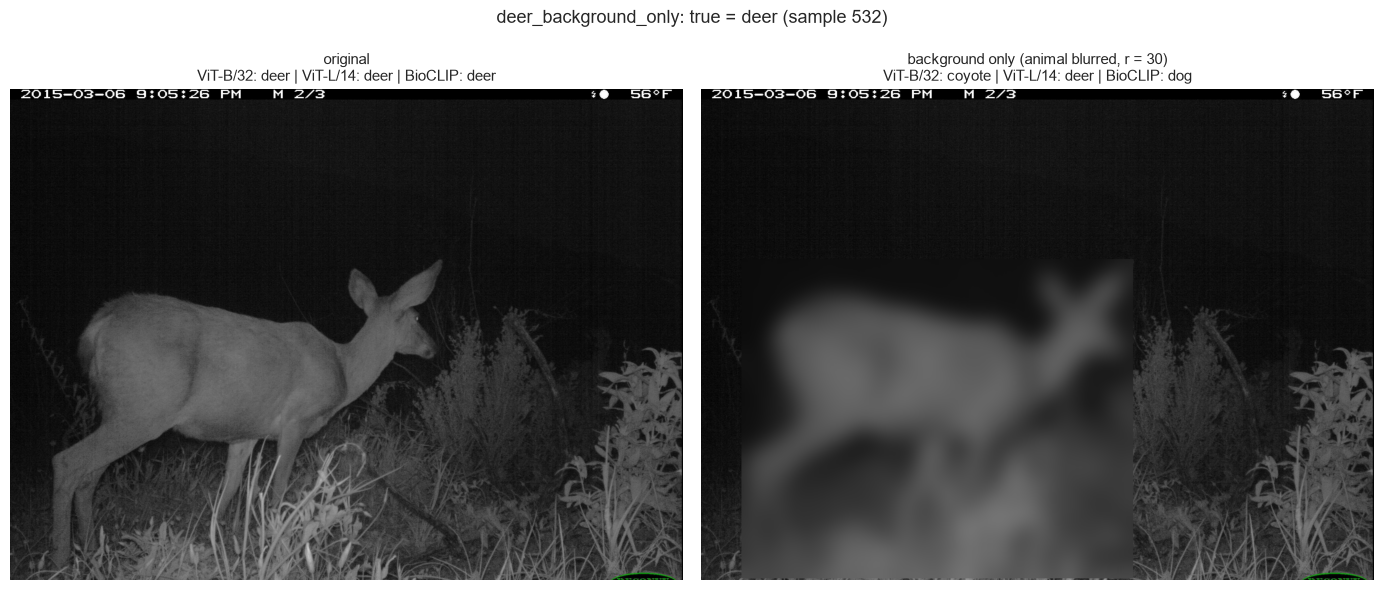

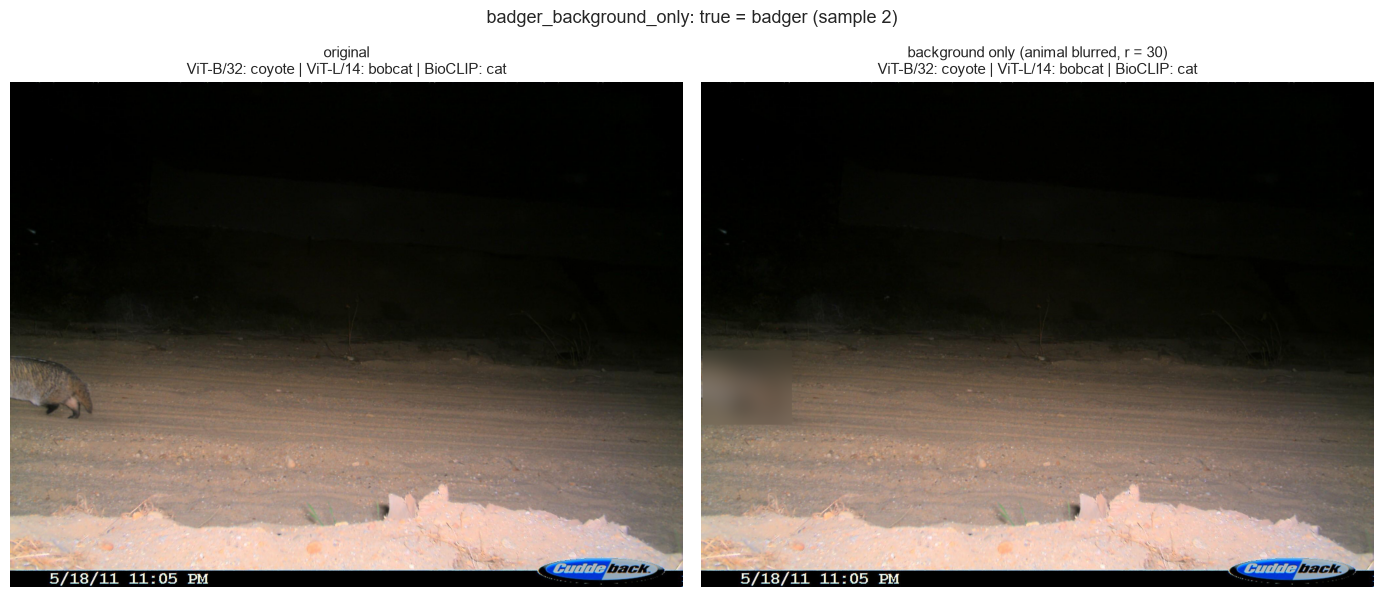

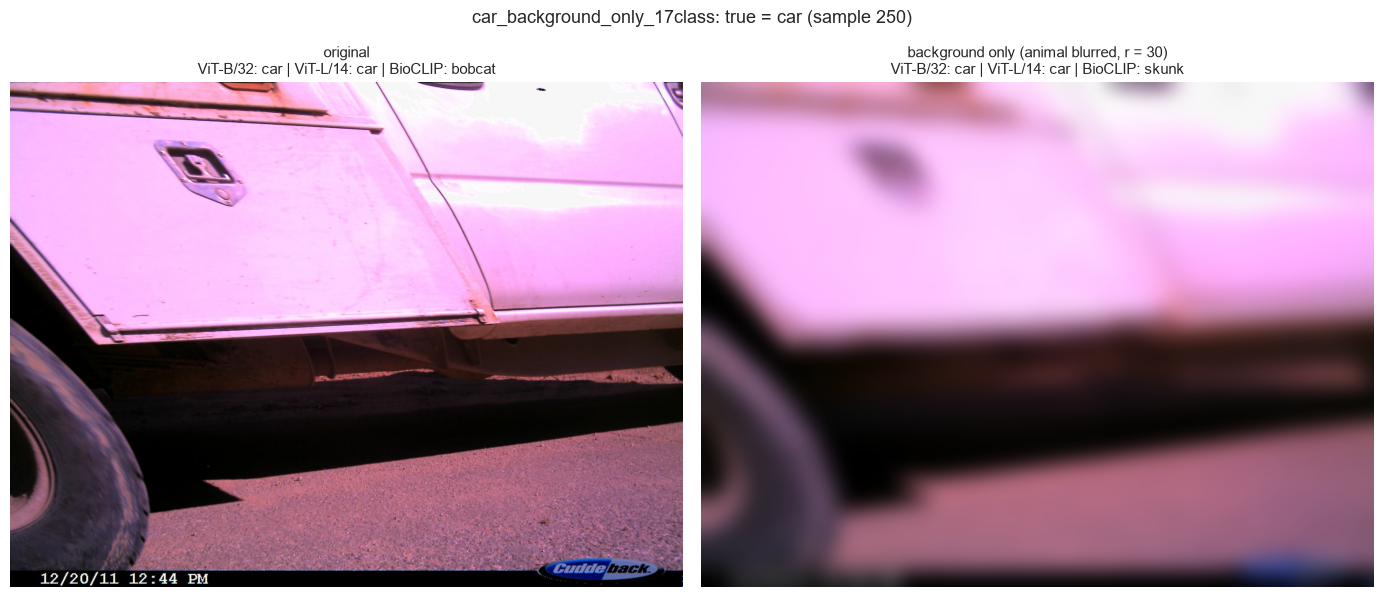

In [23]:
from imaging import load_image, scaled_box, make_variant
from habitats import HABITAT_MAP
def preds(df, sid, exp, cond):
    q = df.query("sample_id == @sid and experiment == @exp and condition == @cond and prompt == 'neutral'")
    return " | ".join(f"{r.model}: {r.prediction}" for r in q.itertuples())
def first_sample(df, sp, exp): return int(df.query("species == @sp and experiment == @exp").sample_id.min())
def render(smp, sid, variant):
    r = smp.set_index("sample_id").loc[sid]; img = load_image(r.file_name)
    return make_variant(img, scaled_box(img, r.x, r.y, r.w, r.h, r.json_w, r.json_h), variant, sid)
def panel(name, df, smp, sid, items):
    fig, axs = plt.subplots(1, len(items), figsize=(7 * len(items), 6.4)); axs = np.atleast_1d(axs)
    for ax, (variant, exp, cond, title) in zip(axs, items):
        ax.imshow(render(smp, sid, variant)); ax.axis("off"); ax.set_title(f"{title}\n{preds(df, sid, exp, cond)}", fontsize=11)
    fig.suptitle(f"{name}: true = {smp.set_index('sample_id').loc[sid].species} (sample {sid})", fontsize=13); fig.tight_layout()
    fig.savefig(FIG / f"panel_{name}.png", dpi=150); plt.show()
D16, D17 = RUNS["16c-Q"], RUNS["17c-G"]
for sp in ("dog", "opossum"):
    sid = first_sample(D16, sp, "exp1"); panel(f"{sp}_full_vs_ultratight", D16, S16, sid, [("crop_full", "exp1", "full", "full context (100 %)"), ("crop_ultra_tight", "exp1", "ultra_tight", "ultra-tight (0 %)")])
sid = first_sample(D16, "raccoon", "exp2_mismatch"); h1, h2 = HABITAT_MAP["raccoon"][:2]
panel("raccoon_mismatched_backgrounds", D16, S16, sid, [("orig", "exp2_baseline", "original", "original"), (f"mismatch_{h1}", "exp2_mismatch", h1, f"{h1} background"), (f"mismatch_{h2}", "exp2_mismatch", h2, f"{h2} background")])
for sp in ("deer", "badger"):
    sid = first_sample(D16, sp, "exp4"); panel(f"{sp}_background_only", D16, S16, sid, [("orig", "exp2_baseline", "original", "original"), ("bgonly", "exp4", "bg_only_blur30", "background only (animal blurred, r = 30)")])
sid = first_sample(D17, "car", "exp4")
panel("car_background_only_17class", D17, sample17, sid, [("orig", "exp2_baseline", "original", "original"), ("bgonly", "exp4", "bg_only_blur30", "background only (animal blurred, r = 30)")])

## 12. Export

In [24]:
(S16.drop(columns=["size_bin"], errors="ignore")).to_csv(OUT / "sample_points_16class.csv", index=False)
sample17.to_csv(OUT / "sample_points_17class.csv", index=False)
for r in RUNS: R[r]["summary"].round(3).to_csv(OUT / f"summary_{r}.csv")
detailed = {"benchmark": "paper / JK (17 classes)", "primary_run": PRIMARY, "runs": {r: S(r).round(3).reset_index().to_dict("records") for r in RUNS},
            "tables": sorted(TABLES), "claims_reproduced": {r: int((claims[r] == "YES").sum()) for r in RUNS_C}, "n_claims": len(claims), "animal_run_meta": metaA}
(OUT / "detailed_results.json").write_text(json.dumps(detailed, indent=2, default=str))
print(len(TABLES), "tables ->", OUT); print(*sorted(p.name for p in FIG.iterdir()), sep="\n")

23 tables -> C:\Users\PC\Desktop\Programs\wildlife_context_repro\results\notebook_report
eda_accuracy_cds_vs_animal_size.png
eda_calibration.png
eda_cds_vs_animal_size_per_species.png
eda_day_vs_night.png
eda_species_by_level.png
fig01_accuracy_vs_context.png
fig02_confidence_vs_context.png
fig03_per_species_cds_16cG.png
fig03_per_species_cds_16cQ.png
fig_background_only.png
fig_confusion_16cG_full_context.png
fig_confusion_16cQ_full_context.png
fig_confusion_17cG_full_context.png
fig_mismatch_per_habitat.png
fig_prompt_sensitivity.png
panel_badger_background_only.png
panel_car_background_only_17class.png
panel_deer_background_only.png
panel_dog_full_vs_ultratight.png
panel_opossum_full_vs_ultratight.png
panel_raccoon_mismatched_backgrounds.png
table03_per_species_cds_colored.png
